# Solar filament segmentation: the complete pipeline

IEEE / Kaggle **Solar Filament Segmentation Challenge 2026**. This notebook runs the whole system, from loading the libraries to writing `submission.csv`.

```
GONG H-alpha frame (2048 px)
 -> 3 hand-designed input channels at 1536 px
 -> 3 U-Nets (ConvNeXt-T DINOv3 encoder) x 4-flip TTA, averaged
 -> probability map
 -> connected components (p >= 0.60, >= 240 px)
 -> learned keep/drop filter
 -> stage 2: every kept filament re-segmented at native 2048 px (2 refiners)
 -> COCO-RLE submission
```

| | Pooled PQ (fold 0, 141 held-out images) | Public LB |
|---|---|---|
| Human vs human: one annotator scored against another (the 67 images with 2–3 annotators) | 0.350 | n/a |
| Best single member (v24) | 0.449 | 0.39 |
| 3-member ensemble + filter (stage 1) | 0.457 | 0.39 |
| **This system** (stage 1 + refiner) | **0.468** | **0.40** |
| This system on the same 67 images as the human row | 0.464 | n/a |

**What runs by default.**
- Loads the shipped fp16 weights from `weights/` and the fitted filter.
- Validates on the 141 fold-0 maps stored in `artifacts/`; the stage-1 part needs CPU only, and refining the 948 kept validation filaments takes about 6 minutes (the crops are prepared on the CPU, so a GPU barely shortens it).
- Segments the test set; on a Tesla T4 this takes about 30 minutes (10.0 s per image, of which the refiner takes 1.9 s).
- Draws every figure.
- Checks the ONNX export.

**Optional switches** (set in the next cell or as environment variables):
- Recompute the validation maps from the weights.
- Refit the filter.
- Train: a quick smoke run, any of the three member recipes, or the teacher–student recipe on unlabelled GONG frames.
- Train a refiner: a smoke run, or the full recipe.

**Sections:**
1. Settings
2. Libraries
3. Data
4. The models
5. Training (optional)
6. Validation maps and the filter
7. Stage 2: the refiner
8. Validation report
9. Test inference and submission
10. Segmentations with bounding boxes
11. Learning curves
12. ONNX
13. Summary

Every function called here lives in the `filament/` package. Each one is short and documented, and the docstrings carry the reasoning and the measurements behind each choice.

## 1. Settings
Each switch can also be set as an environment variable, which is how the reproducibility run on Kaggle sets them.

In [1]:
import os
from pathlib import Path

def env_flag(name, default):
    return os.environ.get(name, str(default)).strip().lower() in ('1', 'true', 'yes', 'on')

REPO = Path(os.environ.get('FILAMENT_REPO', Path.cwd())).resolve()
DATA_ROOT = os.environ.get('FILAMENT_DATA')                 # None: look in /kaggle/input, ./data, ../data
WORK = Path(os.environ.get('FILAMENT_WORK', REPO / 'outputs'))
REPREDICT_VALIDATION = env_flag('FILAMENT_REPREDICT_VALIDATION', False)   # recompute fold-0 maps (GPU ~12 min)
REFIT_FILTER = env_flag('FILAMENT_REFIT_FILTER', False)                   # refit the filter (CPU ~10 min)
RUN_TEST = env_flag('FILAMENT_RUN_TEST', True)
MAX_TEST_IMAGES = int(os.environ.get('FILAMENT_MAX_TEST', 0)) or None     # None = all test images
MAX_VAL_IMAGES = int(os.environ.get('FILAMENT_MAX_VAL', 0)) or None       # quick check on a few validation images only
RUN_ONNX = env_flag('FILAMENT_RUN_ONNX', True)
ONNX_IMAGES = int(os.environ.get('FILAMENT_ONNX_IMAGES', 3))
TRAINING = os.environ.get('FILAMENT_TRAINING', 'off')      # off | smoke | student | v24 | v27 | v31
UNLABELLED_DIR = os.environ.get('FILAMENT_UNLABELLED')     # folder of unlabelled GONG frames (student recipe)
RUN_REFINER = env_flag('FILAMENT_REFINER', True)           # stage 2; False reproduces the stage-1 system (PQ 0.457)
REFINER_TRAINING = os.environ.get('FILAMENT_REFINER_TRAINING', 'off')   # off | smoke | full
USE_TRAINED_REFINERS = REFINER_TRAINING == 'full' or env_flag('FILAMENT_REFINER_USE_TRAINED', False)
SAVE_RELEASE_ARTIFACTS = env_flag('FILAMENT_SAVE_RELEASE', False)   # write refits back into weights/ and artifacts/

assert (REPO / 'filament').is_dir(), f'run this notebook from the repository root (no filament/ under {REPO})'
WORK.mkdir(parents=True, exist_ok=True)
FIGURES = WORK / 'figures'; FIGURES.mkdir(exist_ok=True)
print({k: v for k, v in dict(REPO=REPO, WORK=WORK, REPREDICT_VALIDATION=REPREDICT_VALIDATION, REFIT_FILTER=REFIT_FILTER,
                              RUN_TEST=RUN_TEST, MAX_TEST_IMAGES=MAX_TEST_IMAGES, RUN_ONNX=RUN_ONNX, TRAINING=TRAINING,
                              RUN_REFINER=RUN_REFINER, REFINER_TRAINING=REFINER_TRAINING).items()})

{'REPO': PosixPath('/kaggle/working/repo'), 'WORK': PosixPath('/kaggle/working/repo/outputs'), 'REPREDICT_VALIDATION': True, 'REFIT_FILTER': True, 'RUN_TEST': True, 'MAX_TEST_IMAGES': None, 'RUN_ONNX': True, 'TRAINING': 'smoke', 'RUN_REFINER': True, 'REFINER_TRAINING': 'full'}


## 2. Libraries
The pinned versions are in `requirements.txt`. If a package is missing, the next cell installs it from that file. It never reinstalls a package that is already present, such as the platform's own CUDA build of PyTorch.

In [2]:
import importlib.util, re, subprocess, sys
pins = {re.split('[=<>]', line)[0].strip().lower(): line.strip()
        for line in (REPO / 'requirements.txt').read_text().splitlines() if line.strip() and not line.startswith('#')}
modules = {'opencv-python-headless': 'cv2', 'scikit-learn': 'sklearn', 'pycocotools': 'pycocotools', 'timm': 'timm',
           'onnx': 'onnx', 'onnxruntime-gpu': 'onnxruntime', 'onnxruntime': 'onnxruntime', 'tqdm': 'tqdm'}
missing = sorted({pins[p] for p, m in modules.items() if p in pins and importlib.util.find_spec(m) is None})
if missing:
    print('installing', missing)
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *missing])
sys.path.insert(0, str(REPO))

installing ['onnxruntime-gpu==1.22.0']


In [3]:
import json, time, warnings
import numpy as np, pandas as pd, torch, matplotlib.pyplot as plt
from IPython.display import display
from tqdm.auto import tqdm

from pycocotools import mask as mask_utils
from filament import (config, data, preprocess, model, inference, decode, instance_filter, metrics, submission,
                      maps as mapstore, pipeline, timing, training, pseudo_labels, refiner, viz)

viz.style()
torch.manual_seed(0); np.random.seed(0)
DEVICE = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')
CFG = config.SystemConfig()
ENV = pipeline.environment()
T_START = time.time()
RESULTS = {'environment': ENV}

def save(fig, name):
    fig.savefig(FIGURES / f'{name}.png', bbox_inches='tight')
    plt.show()

display(pd.Series(ENV, name='environment').to_frame())
if DEVICE.type == 'cpu':
    print('No GPU: inference runs on CPU (about 1 min per test image). Set FILAMENT_MAX_TEST to try a few images.')

,environment
python,3.13.16
platform,Linux-6.18.55+-x86_64-with-glibc2.39
torch,2.11.0+cu130
timm,1.0.30
numpy,2.1.3
pandas,2.3.3
opencv,4.14.0
scikit-learn,1.6.1
scipy,1.16.3
pycocotools,installed


## 3. Data
MAGFiLO stores one COCO "image" entry per (image, annotator) pair, which we call a **record**. The metric scores a prediction against every record of an image and pools the counts. Fold 0 is the validation fold for every number in this notebook. It has 141 images and is stratified by GONG site and by filament-count quartile.

CompetitionPaths(root=PosixPath('/kaggle/input/competitions/filament-segmentation-2026/MAGFiLO_1.0_Kaggle_2026'), annotations=PosixPath('/kaggle/input/competitions/filament-segmentation-2026/MAGFiLO_1.0_Kaggle_2026/train/MAGFiLO_1.0_Annotations_kaggle2026_train.json'), train_images=PosixPath('/kaggle/input/competitions/filament-segmentation-2026/MAGFiLO_1.0_Kaggle_2026/train/train_images'), test_images=PosixPath('/kaggle/input/competitions/filament-segmentation-2026/MAGFiLO_1.0_Kaggle_2026/test/test_images'))


,dataset
images,707
records,1154
filaments,8199
images_by_annotators,"{1: 411, 2: 145, 3: 151}"
sites,"{'L': 127, 'C': 125, 'M': 125, 'B': 118, 'T': ..."
years,2011-2022
train_images,566
validation_images,141
test_images,180


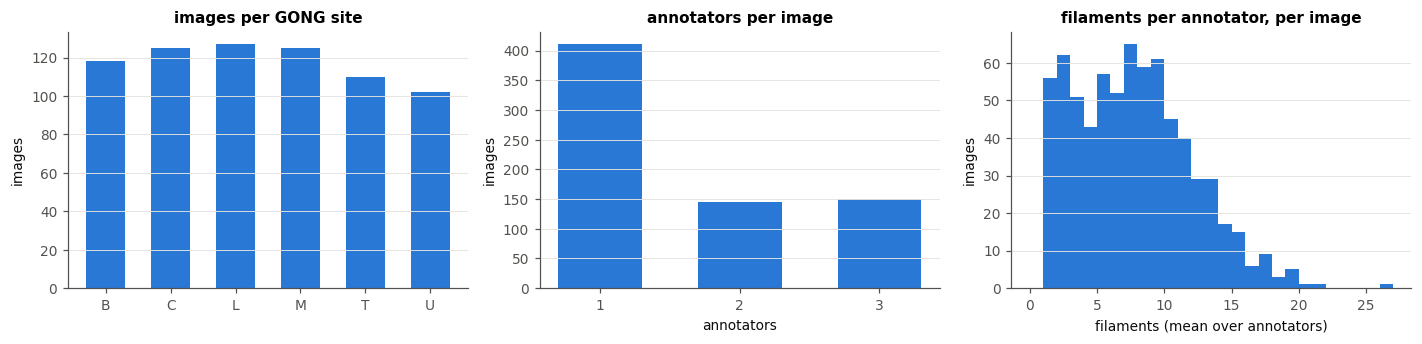

In [4]:
PATHS = data.find_competition_data(DATA_ROOT)
INDEX = data.load_annotations(PATHS.annotations)
FOLDS = data.load_folds(REPO / 'artifacts' / 'fold_manifest.csv')
VAL_FILES = FOLDS.loc[FOLDS['fold'] == 0, 'filename'].tolist()
TRAIN_FILES = FOLDS.loc[FOLDS['fold'] != 0, 'filename'].tolist()
TEST_FILES = data.list_images(PATHS.test_images)
MEDOID = data.medoid_records(INDEX)
meta = data.annotation_metadata(INDEX)
RESULTS['data'] = {**meta, 'train_images': len(TRAIN_FILES), 'validation_images': len(VAL_FILES), 'test_images': len(TEST_FILES)}
print(PATHS)
display(pd.Series(RESULTS['data'], name='dataset').to_frame())
IMAGES = data.image_table(INDEX)
save(viz.data_overview(IMAGES), 'data_overview')

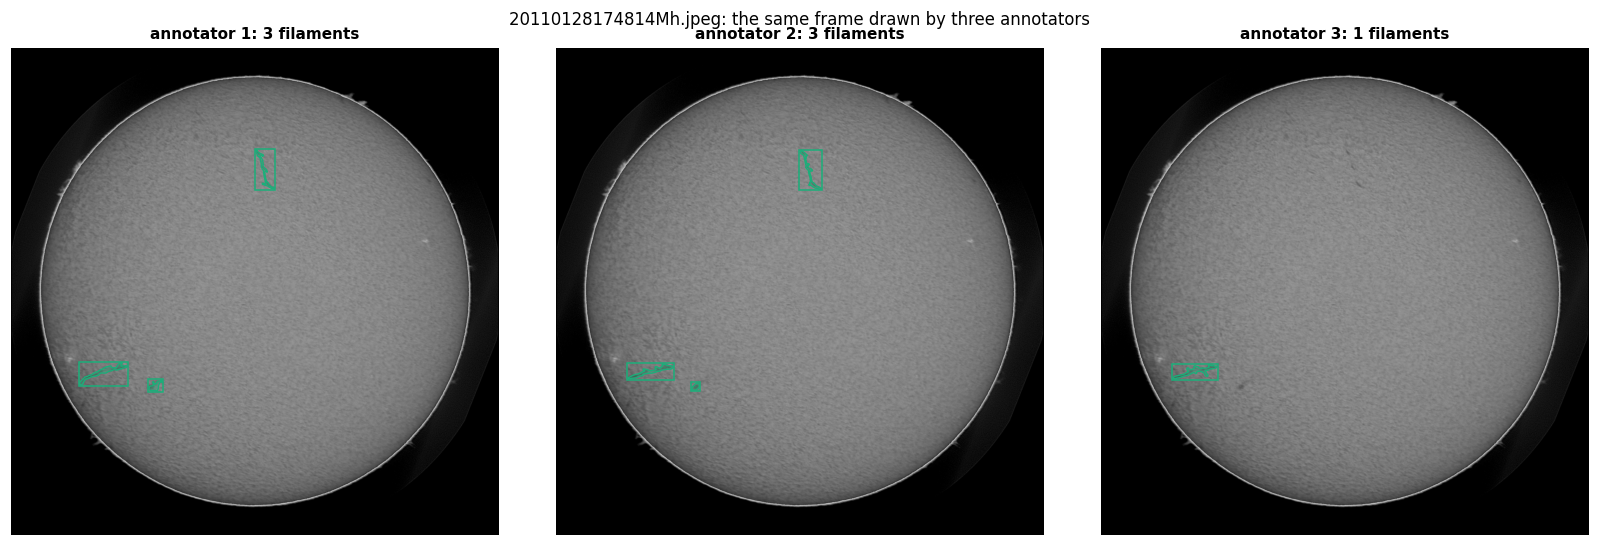

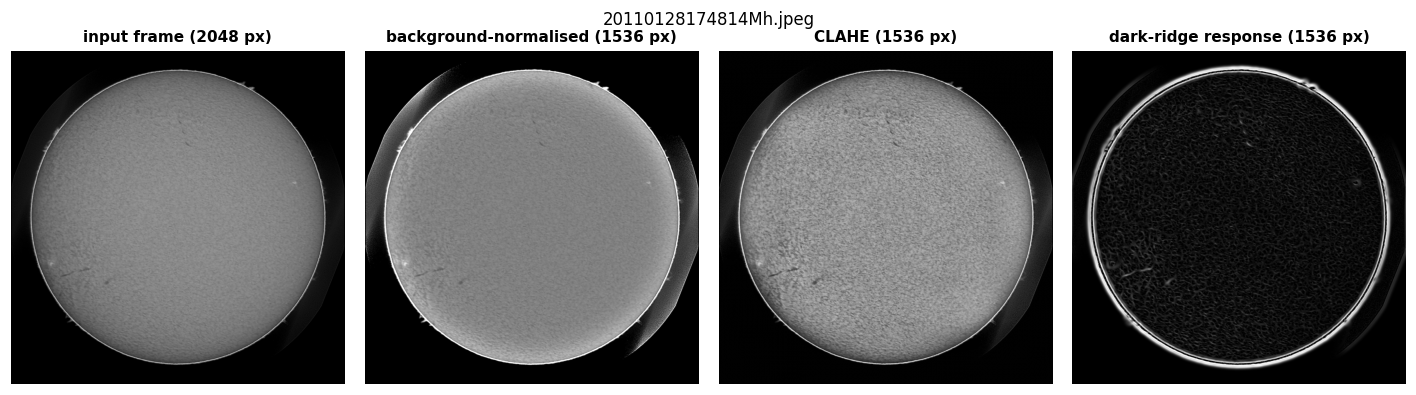

In [5]:
# One validation image with three annotators: how much the humans disagree, and the network's three input channels.
example = next(f for f in VAL_FILES if len(INDEX.records_by_file[f]) == 3)
image = data.read_gray(PATHS.train_images / example)
gt_sets = data.ground_truth_sets(INDEX, example)
fig, axes = plt.subplots(1, len(gt_sets), figsize=(5 * len(gt_sets), 5))
for a, (ax, gt) in enumerate(zip(axes, gt_sets)):
    viz._image_axis(ax, image, f'annotator {a + 1}: {len(gt)} filaments')
    viz.draw_instances(ax, gt, viz.COLORS[2], box=True)
fig.suptitle(f'{example}: the same frame drawn by three annotators'); fig.tight_layout()
save(fig, 'annotators')
save(viz.show_channels(image, preprocess.network_input(image, CFG.input), example), 'input_channels')

## 4. The models
**Three members, one architecture.** Each member is a `FilamentUNet` with these parts:
- **Encoder:** a ConvNeXt-Tiny with DINOv3-distilled initial weights. It produces features at strides 4, 8, 16 and 32, and each feature map is GroupNorm-ed.
- **Decoder:** a U-Net with blocks of 256, 128 and 64 channels.
- **Stem:** a full-resolution stem with 16 channels. It is the only path that sees the 1–2 px edges of a filament.
- **Head:** two outputs, the filament mask and the filament *spine* (centre line).

The model has 31.9 M parameters. GroupNorm is used everywhere because training runs at batch size 1.

**The members differ only in their training targets and augmentation:**

| Member | Target annotator | Extra augmentation | Epochs (kept) | Fold-0 PQ (own filter) | Public LB |
|---|---|---|---|---|---|
| v24 | medoid (agrees most with the others) | — | 23 of 35 (best epoch, 17) | 0.449 | 0.39 |
| v27 | random record per sample | rotation ±15°, scale ±12.5% | 26 (best epoch, 21) | 0.443 | 0.38 |
| v31 | 50/50 medoid / random | as v27 | 30 (final epoch) | 0.438 | 0.38 |

**The ensemble** averages the sigmoid probabilities over 3 members × 4 flips and scores **0.457**. It is the only change to the dense network that cleared our +0.005 adoption bar, which is set above the seed noise of ±0.004. A second stage, the refiner of Section 7, then raises the system to **0.468**.

**Measured and rejected** (each within seed noise or worse):
- Wider and higher-resolution decoders, and a Mask2Former decoder (its stride-4 masks cap PQ at 0.64, against 0.74 for this head).
- Soft annotator-mean targets.
- Heavy augmentation.
- Inference above 1536 px.
- A fourth member.

**Weight files.** Each member is stored as fp16 (61 MB each; fp32 would exceed GitHub's 100 MB file limit) and loaded back to fp32. Rounding the weights to fp16 moves the probabilities by at most 1.6e-6 (`provenance/check_release.log`).

**Where each member comes from.** Each member was trained by one version of our research notebook on Kaggle, `alok158/solar-filament` (versions 24, 27 and 31; table below). That notebook embeds the research library this package was refactored from, and `provenance/check_release.py` showed the two give identical results on the same inputs. Copies of the three notebook versions are in `training_notebooks/`; the Kaggle notebooks are made public when the competition closes. Each checkpoint went from its version's output into a private Kaggle dataset and was converted to the fp16 file in `weights/`; the fingerprints are checked when the weights load. Section 5 reruns the same recipes (`TRAINING = v24 | v27 | v31`).

In [6]:
CARDS = json.loads((REPO / 'weights' / 'MODELS.json').read_text())
MEMBERS = model.load_members(REPO / 'weights', CFG.members, DEVICE)
rows = []
for name, net in zip(CFG.members, MEMBERS):
    state, meta_ = model.read_member(REPO / 'weights' / f'{name}.fp16.pt')
    card = CARDS['members'][name]
    fp = model.weights_fingerprint(state)
    assert fp == card['fingerprint'], f'{name}: weights fingerprint {fp} does not match MODELS.json'
    rows.append({'member': name, 'targets': card['targets'], 'schedule': card['schedule'],
                 'fold0_PQ': card['fold0_pq_filtered'], 'public_LB': card['public_lb'],
                 'parameters_M': round(model.count_parameters(net)['total'] / 1e6, 2), 'file_MB': card['megabytes'],
                 'fingerprint': fp})
MODEL_TABLE = pd.DataFrame(rows).set_index('member')
display(MODEL_TABLE)
PROVENANCE = pd.DataFrame([{'member': name, 'trained by': f"{c['trained_by']['kaggle_notebook']}, version {c['trained_by']['version']}",
                            'completed': c['trained_by']['completed'], 'run': c['trained_by']['run'],
                            'copy in this repository': c['trained_by']['copy']}
                           for name, c in CARDS['members'].items() if 'trained_by' in c]).set_index('member')
display(PROVENANCE)
display(pd.Series(CARDS['common'], name='shared recipe').to_frame())
display(pd.Series(model.count_parameters(MEMBERS[0]), name='parameters').to_frame())

,targets,schedule,fold0_PQ,public_LB,parameters_M,file_MB,fingerprint
member,,,,,,,
v24,medoid annotator (the record agreeing most wit...,35 epochs requested; stopped by the session bu...,0.4494,0.39,31.93,61.0,d3a2e435f53e8dbe
v27,a random annotator record per sample (label au...,"26 epochs, best validated epoch (21) kept",0.4427,0.38,31.93,61.0,94c3a2a2d740398a
v31,50/50 medoid / random annotator per sample,"30 epochs, final epoch kept (no selection on v...",0.4375,0.38,31.93,61.0,d749aa06b75a627c


,trained by,completed,run,copy in this repository
member,,,,
v24,"alok158/solar-filament, version 24",2026-10-10,23 of 35 epochs (stopped by the 8 h budget); b...,training_notebooks/v24.ipynb
v27,"alok158/solar-filament, version 27",2026-10-14,26 of 26 epochs (~7 h); best fold-0 epoch 24 kept,training_notebooks/v27.ipynb
v31,"alok158/solar-filament, version 31",2026-10-16,30 of 30 epochs (one 9.8 h session); final epo...,training_notebooks/v31.ipynb


,shared recipe
architecture,FilamentUNet: ConvNeXt-Tiny encoder (timm conv...
parameters,31900000.0
input,"1536 x 1536, 3 channels (background-normalised..."
training_data,MAGFiLO folds 1-4 (566 images); fold 0 (141 im...
optimiser,"AdamW lr 3e-4 (encoder x0.1), weight decay 1e-..."
loss,BCE + 0.5 per-instance Dice + 0.5 image Dice +...
hardware,"one NVIDIA Tesla T4 (Kaggle), 13-17 min per epoch"


,parameters
encoder,27818592
decoder,4110528
stem,2800
head,66
total,31931986


In [7]:
# Feature-map shapes through the network, traced with forward hooks on a small input and scaled to 1536 px.
probe_size = 256
shapes = []
hooks = [m.register_forward_hook(lambda mod, inp, out, n=n: shapes.append((n, tuple(out.shape))))
         for n, m in [('stem', MEMBERS[0].stem), ('final', MEMBERS[0].final), ('head', MEMBERS[0].head)]
         + [(f'decoder block {i}', b) for i, b in enumerate(MEMBERS[0].blocks)]]
with torch.no_grad():
    MEMBERS[0](torch.zeros(1, 3, probe_size, probe_size, device=DEVICE))
for h in hooks:
    h.remove()
table = []
for name, shape in shapes:
    table.append({'stage': name, 'channels': shape[1], 'stride': probe_size // shape[-1],
                  'size at 1536 px': f'{1536 * shape[-1] // probe_size}^2'})
for i, ch in enumerate(MEMBERS[0].encoder.feature_info.channels()):
    table.insert(i, {'stage': f'encoder stage {i}', 'channels': ch, 'stride': MEMBERS[0].encoder.feature_info.reduction()[i],
                     'size at 1536 px': f'{1536 // MEMBERS[0].encoder.feature_info.reduction()[i]}^2'})
display(pd.DataFrame(table))

,stage,channels,stride,size at 1536 px
0,encoder stage 0,96,4,384^2
1,encoder stage 1,192,8,192^2
2,encoder stage 2,384,16,96^2
3,encoder stage 3,768,32,48^2
4,decoder block 0,256,16,96^2
5,decoder block 1,128,8,192^2
6,decoder block 2,64,4,384^2
7,stem,16,1,1536^2
8,final,32,1,1536^2
9,head,2,1,1536^2


## 5. Training (optional)
Set `TRAINING` in Settings, or the `FILAMENT_TRAINING` environment variable, to choose a mode:

| Mode | What runs | Time on one T4 |
|---|---|---|
| `off` (default) | nothing; the shipped weights are used | — |
| `smoke` | the teacher–student recipe at 384 px on 8 + 8 images for 2 epochs. Proves the code path end to end and draws a live learning curve | ~3 min |
| `v24`, `v27`, `v31` | a member recipe from the DINOv3 initialisation (needs internet: downloads the encoder weights from the Hugging Face hub, no token) | 8–10 h |
| `student` | the teacher–student recipe on unlabelled GONG frames in `FILAMENT_UNLABELLED` | ~6.5 h |

**Teacher–student is the best use of unlabelled data we measured.**
1. The deployed ensemble labels unlabelled GONG frames from 2023–2026 with *soft* maps.
2. The frames are re-weighted toward the validation era's filament-count distribution, since solar maximum shows more filaments.
3. A student starts from v24 and trains on 566 labelled + 566 pseudo-labelled samples per epoch.

**Results:**
- The student beat the identical schedule on labelled data only by **+0.014 PQ**, a gain in every bootstrap resample over images.
- One student equals the 3-model teacher at a third of the inference cost.
- Adding the student to the ensemble does not help.

**Data rule.** Unlabelled frames are used for training only, and they postdate the labelled set. Inference sees only the test image itself.

In [8]:
TRAIN_HISTORY = None
if TRAINING == 'off':
    print('training skipped: the shipped weights are used (set TRAINING to smoke / student / v24 / v27 / v31)')
else:
    from dataclasses import replace
    smoke = TRAINING == 'smoke'
    recipe = config.RECIPES['student' if smoke else TRAINING]
    if smoke:
        recipe = replace(recipe, name='smoke', input_size=384, epochs=2, val_every=1, pseudo_per_epoch=8, num_workers=0,
                         grad_checkpointing=False)
    train_files = TRAIN_FILES[:8] if smoke else TRAIN_FILES
    val_files = VAL_FILES[:4] if smoke else VAL_FILES
    out_dir = WORK / 'training' / recipe.name
    pseudo_set, weights = None, None
    if recipe.pseudo_per_epoch:
        if UNLABELLED_DIR:
            frames = sorted(p for p in Path(UNLABELLED_DIR).rglob('*') if p.suffix.lower() in ('.jpg', '.jpeg', '.png'))
        else:
            assert smoke, 'the student recipe needs FILAMENT_UNLABELLED (a folder of unlabelled GONG frames)'
            frames = [PATHS.train_images / f for f in TRAIN_FILES[8:16]]     # smoke only: labels ignored
            print('smoke: 8 training images stand in for unlabelled frames (their labels are not used)')
        if smoke:
            frames = frames[:8]
        teacher_input = config.InputConfig(input_size=recipe.input_size)
        labels = pseudo_labels.teacher_label(MEMBERS, frames, out_dir / 'teacher_maps', DEVICE, teacher_input,
                                             CFG.inference, CFG.decode, progress=tqdm)
        reference = pseudo_labels.reference_counts(mapstore.MapStore(REPO / 'artifacts' / 'fold0_maps.npz'), CFG.decode)
        weights = pseudo_labels.prior_shift_weights(labels['teacher_instances'], reference)
        print(f'teacher: median {labels.teacher_instances.median():.0f} instances/frame vs {np.median(reference):.0f} on '
              f'fold 0; weights {weights.min():.2f}-{weights.max():.2f}, effective sample size '
              f'{pseudo_labels.effective_sample_size(weights):.0f}/{len(weights)}')
        from filament.datasets import PseudoLabelDataset
        pseudo_set = PseudoLabelDataset(list(zip(labels['frame'], labels['maps'])), recipe)
    init = REPO / 'weights' / f'{recipe.init_from}.fp16.pt' if recipe.init_from else None
    result = training.fit(recipe, train_files, val_files, PATHS.train_images, INDEX, MEDOID, out_dir, DEVICE,
                          init_weights=init, pseudo=pseudo_set, pseudo_weights=weights, progress=tqdm)
    TRAIN_HISTORY = result.history
    display(TRAIN_HISTORY)
    print('trained weights:', result.weights, '| fingerprint', result.meta['fingerprint'])
    RESULTS['training'] = {'mode': TRAINING, **{k: v for k, v in result.meta.items() if k != 'recipe'}}

smoke: 8 training images stand in for unlabelled frames (their labels are not used)


teacher:   0%|          | 0/8 [00:00<?, ?it/s]

teacher: median 0 instances/frame vs 9 on fold 0; weights 0.20-0.20, effective sample size 8/8


train:   0%|          | 0/16 [00:00<?, ?it/s]

epoch=1 train_loss=0.9120 lr_factor=1.0000 skipped_batches=0 val_pq=0.0000 val_sq=0.0000 val_rq=0.0000 val_tp=0 val_fp=0 val_fn=25 minutes=0.1713


train:   0%|          | 0/16 [00:00<?, ?it/s]

epoch=2 train_loss=0.9093 lr_factor=0.5000 skipped_batches=0 val_pq=0.0000 val_sq=0.0000 val_rq=0.0000 val_tp=0 val_fp=0 val_fn=25 minutes=0.0551


,epoch,train_loss,lr_factor,skipped_batches,val_pq,val_sq,val_rq,val_tp,val_fp,val_fn,minutes
0,1,0.911970,1.0,0,0.0,0.0,0.0,0,0,25,0.171337
1,2,0.909272,0.5,0,0.0,0.0,0.0,0,0,25,0.055114


trained weights: /kaggle/working/repo/outputs/training/smoke/smoke.fp16.pt | fingerprint ae3d47461c2c5e54


## 6. Validation maps and the instance filter
The ensemble's probability maps for the 141 fold-0 images are stored in `artifacts/fold0_maps.npz` as uint8 (11 MB), so this section needs no GPU. Set `REPREDICT_VALIDATION` to recompute the maps from the weights and compare them with the stored ones.

**How the filter works.** It is gradient-boosted trees on 15 features computed from each candidate's own mask and the two probability maps. It predicts the fraction of annotators who drew that filament, and candidates below a threshold are dropped. The threshold comes from a derivation: dropping a candidate with match probability p and IoU u changes pooled PQ by −p·u in the numerator and −½ in the denominator, so dropping helps exactly when **p < ½·PQ/SQ**.

**How it is fit.** It is fit on fold 0 only, with five models cross-fitted by observation date. Every validation number below uses *out-of-fold* scores.

In [9]:
SHIPPED_MAPS = REPO / 'artifacts' / 'fold0_maps.npz'
if REPREDICT_VALIDATION:
    t0 = time.time()
    VAL_MAPS = pipeline.predict_validation_maps(MEMBERS, VAL_FILES, PATHS.train_images, WORK / 'fold0_maps.npz', DEVICE,
                                                CFG, progress=tqdm)
    RESULTS['validation_maps'] = {'repredicted': True, 'minutes': round((time.time() - t0) / 60, 1)}
    if SHIPPED_MAPS.exists():
        shipped = mapstore.MapStore(SHIPPED_MAPS)
        diffs = []
        for f in VAL_FILES:
            a, b = VAL_MAPS[f][0], shipped[f][0]
            d = np.abs(np.round(a * 255) - np.round(b * 255))
            diffs.append((d.max(), d.mean(), (d > 2).mean()))
        diffs = np.array(diffs)
        RESULTS['validation_maps'].update(max_abs_diff_255=float(diffs[:, 0].max()), mean_abs_diff_255=float(diffs[:, 1].mean()),
                                          share_pixels_diff_gt2=float(diffs[:, 2].mean()))
        print('re-predicted vs shipped maps:', RESULTS['validation_maps'])
    if SAVE_RELEASE_ARTIFACTS:
        import shutil; shutil.copy2(WORK / 'fold0_maps.npz', SHIPPED_MAPS)
else:
    VAL_MAPS = mapstore.MapStore(SHIPPED_MAPS)
    RESULTS['validation_maps'] = {'repredicted': False, 'source': str(SHIPPED_MAPS.relative_to(REPO))}
if MAX_VAL_IMAGES:   # a quick check only: every validation number below then covers these images alone
    VAL_MAPS = VAL_MAPS.subset([example] + [f for f in VAL_MAPS if f != example][:MAX_VAL_IMAGES - 1])
    print(f'FILAMENT_MAX_VAL: validating on {len(VAL_MAPS)} of the 141 images (numbers are not comparable)')
print(len(VAL_MAPS), 'validation maps')

validation maps:   0%|          | 0/141 [00:00<?, ?it/s]

re-predicted vs shipped maps: {'repredicted': True, 'minutes': 18.0, 'max_abs_diff_255': 5.0, 'mean_abs_diff_255': 0.00101412610804781, 'share_pixels_diff_gt2': 7.778194779199912e-08}
141 validation maps


filter table:   0%|          | 0/141 [00:00<?, ?it/s]

evaluate:   0%|          | 0/141 [00:00<?, ?it/s]

filter: unfiltered PQ 0.42223 -> filtered 0.45729 at t=0.3652 (closed form 0.3152); drops 28.5% -> deployed threshold 0.3223
filter refit in 7.4 min


,instance filter
instances,1325.000000
unfiltered_pq,0.422235
unfiltered_sq,0.669712
closed_form,0.315236
threshold,0.365200
filtered_pq,0.457292
auc_matched_any,0.799666
drop_rate,0.284528
deploy_threshold,0.322325


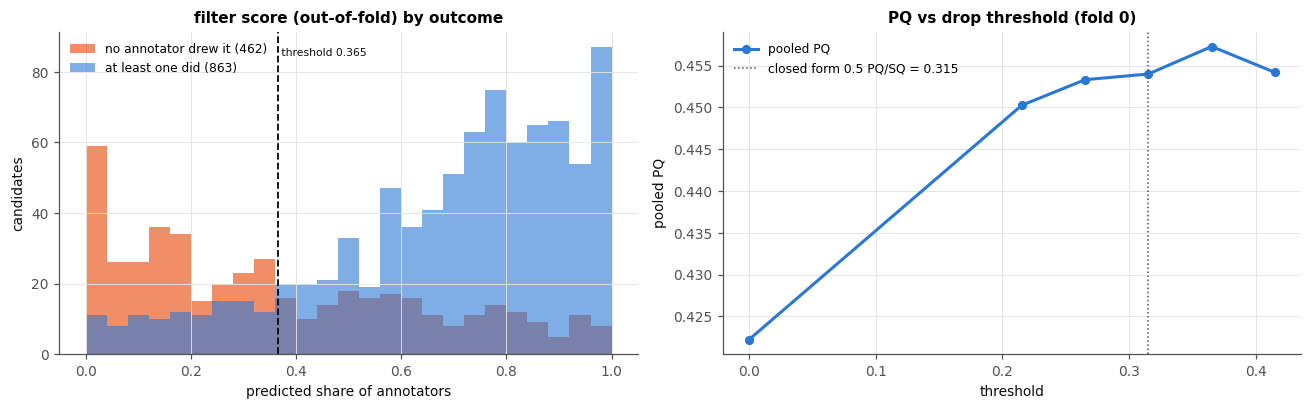

In [10]:
FILTER_PATH = REPO / 'weights' / 'instance_filter.pkl'
if REFIT_FILTER or not FILTER_PATH.exists():
    t0 = time.time()
    FILTER = instance_filter.fit_filter(VAL_MAPS, INDEX, CFG.decode, CFG.filter, progress=tqdm)
    assert FILTER is not None, 'the filter did not beat unfiltered PQ'
    FILTER.save(WORK / 'instance_filter.pkl')
    if SAVE_RELEASE_ARTIFACTS:
        FILTER.save(FILTER_PATH)
    print(f'filter refit in {(time.time() - t0) / 60:.1f} min')
else:
    FILTER = instance_filter.InstanceFilter.load(FILTER_PATH)
report = {k: v for k, v in FILTER.report.items() if k != 'curve'}
RESULTS['filter'] = report
display(pd.Series(report, name='instance filter').to_frame())
save(viz.filter_figure(FILTER.oof, pd.DataFrame(FILTER.report['curve']), FILTER.report['closed_form'],
                       FILTER.report['threshold']), 'filter')

## 7. Stage 2: the refiner
**Why.** The dense network sees the disk at 1536 px, so each instance is a level set of an upsampled map. Its edges can sit a pixel off, and a filament whose probability dips part-way is cut short; truncation is the most common near miss. If every kept instance were replaced by the consensus of the annotators who drew it, fold-0 PQ would rise from 0.457 to 0.652. The headroom is in the outlines, not in which filaments are kept.

**What it does.** Each kept filament gets its own crop at native 2048 px:
- **Crop:** rotated so the filament's long axis is horizontal, 1.8 × its length and 24 px either side, shrunk only if it does not fit 128 × 384.
- **Input, 7 channels:** the 3 image channels at native resolution, the ensemble's mask and spine probabilities, the filament itself (the *seed*), and the other kept filaments.
- **Target:** the share of the annotators who drew this filament that mark each pixel. Whether the filament exists stays the filter's decision.
- **Output:** two refiners (seeds 0 and 1) × 4 flips, averaged and thresholded at 0.40, the pixel threshold that maximises expected IoU when the typical IoU is about 0.65 (0.40 = 0.65 / 1.65). The threshold was fixed before the experiment.
- **Paste-back:** keep the refined components that touch the seed; a pixel claimed by two filaments goes to the higher probability; a filament left with less than half its refined area is absorbed; an empty refinement keeps the seed. Instances stay disjoint.

**Measured on fold 0** (same 948 kept instances on both sides, paired bootstrap over images):

| | PQ | SQ | RQ | IoU / Dice pair means |
|---|---|---|---|---|
| stage 1 | 0.457 | 0.673 | 0.680 | 0.595 / 0.729 |
| **+ refiner** | **0.468** (+0.011, 95% CI [+0.007, +0.014]) | 0.681 | 0.687 | 0.603 / 0.734 |

Each seed alone gains +0.009 (0.466 each). The experiment that adopted the refiner had trained its own pair separately and measured 0.469 (+0.012, 95% CI [+0.009, +0.015]), with every pixel threshold from 0.30 to 0.50 gaining, so the gain reproduces across training runs. Missed, false-alarm and fragmented rates do not change; merged filaments go from 2.6% to 2.7% (human 2.8%). Public LB: 0.39 → 0.40.

**Training happens in this notebook** (switch `REFINER_TRAINING`). `full` is the recipe of the shipped refiners: the ensemble's maps of the 566 training images (never fold 0), candidates decoded at 0.5, 0.6 and 0.7 (12,683 crops), 16 epochs per seed, one seed per GPU (82 min on a T4; about 3.3 h in all with the maps and crops, and it needs internet for the encoder weights). The shipped `weights/refiner_s0.fp16.pt` and `refiner_s1.fp16.pt` were produced by running this section with `full` on Kaggle; `MODELS.json` records the run. `smoke` runs the same code on two images for one epoch.

In [11]:
TRAINED = {}
if REFINER_TRAINING in ('smoke', 'full'):
    from dataclasses import replace
    smoke = REFINER_TRAINING == 'smoke'
    files = TRAIN_FILES[:2] if smoke else TRAIN_FILES
    # 1. The ensemble's maps of the TRAINING images, made exactly as at test time
    #    (smoke: one member, one view, still at the deployed input size so that filaments are found).
    map_cfg = replace(CFG, input=config.InputConfig(), inference=replace(CFG.inference, tta_flips=((),))) if smoke else CFG
    t0 = time.time()
    train_maps = pipeline.predict_validation_maps(MEMBERS[:1] if smoke else MEMBERS, files, PATHS.train_images,
                                                  WORK / 'refiner_train_maps.npz', DEVICE, map_cfg, progress=tqdm)
    minutes_maps = (time.time() - t0) / 60
    # 2. Crops and consensus targets, built in parallel over images (identical to a serial run).
    t0 = time.time()
    crops, targets = refiner.training_set(train_maps, files, PATHS.train_images, INDEX, CFG.refine, progress=tqdm,
                                          workers=max(1, min(4, os.cpu_count() or 1)))
    minutes_crops = (time.time() - t0) / 60
    print(f'{len(crops)} training crops from {len(files)} training images')
    recipe = replace(CFG.refine, epochs=1, batch_size=2) if smoke else CFG.refine
    if len(crops) < recipe.batch_size:
        print('too few training crops for one batch: training skipped')
    else:
        # 3. One refiner per seed (refiner_s0 -> seed 0, refiner_s1 -> seed 1); with two GPUs both train at once.
        devices = [f'cuda:{i}' for i in range(torch.cuda.device_count())] or ['cpu']
        t0 = time.time()
        TRAINED = refiner.fit_refiners(crops, targets, CFG.refiners, devices, WORK / 'refiner_training', recipe,
                                       pretrained=not smoke, num_workers=0 if smoke else 2)
        RESULTS['refiner_training'] = {'mode': REFINER_TRAINING, 'images': len(files), 'crops': len(crops),
                                       'devices': devices, 'minutes_maps': round(minutes_maps, 1),
                                       'minutes_crops': round(minutes_crops, 1),
                                       'minutes_training': round((time.time() - t0) / 60, 1),
                                       'fingerprints': {k: v['fingerprint'] for k, v in TRAINED.items()}}
        display(pd.Series(RESULTS['refiner_training'], name='refiner training').to_frame())
    del crops, targets
else:
    print('refiner training skipped: the shipped refiners are used (set REFINER_TRAINING to smoke / full)')

validation maps:   0%|          | 0/566 [00:00<?, ?it/s]

refiner crops:   0%|          | 0/566 [00:00<?, ?it/s]

12683 training crops from 566 training images


/kaggle/working/repo/filament/refiner.py:395: UserWarning: Converting a tensor with requires_grad=True to a scalar may lead to unexpected behavior.
Consider using tensor.detach() first. (Triggered internally at /pytorch/torch/csrc/autograd/generated/python_variable_methods.cpp:836.)
  total, seen = total + float(loss) * len(x), seen + len(x)
/kaggle/working/repo/filament/refiner.py:395: UserWarning: Converting a tensor with requires_grad=True to a scalar may lead to unexpected behavior.
Consider using tensor.detach() first. (Triggered internally at /pytorch/torch/csrc/autograd/generated/python_variable_methods.cpp:836.)
  total, seen = total + float(loss) * len(x), seen + len(x)


[refiner_s1 on cuda:1] refiner seed 1 epoch 1/16 loss 1.0722


[refiner_s0 on cuda:0] refiner seed 0 epoch 1/16 loss 1.2008


... (27 outputs left out)

[refiner_s1 on cuda:1] refiner seed 1 epoch 15/16 loss 0.3057


[refiner_s0 on cuda:0] refiner seed 0 epoch 16/16 loss 0.3101


[refiner_s1 on cuda:1] refiner seed 1 epoch 16/16 loss 0.3052


,refiner training
mode,full
images,566
crops,12683
devices,"[cuda:0, cuda:1]"
minutes_maps,71.0
minutes_crops,45.1
minutes_training,82.3
fingerprints,"{'refiner_s0': 'e30eab77fcb7127c', 'refiner_s1..."


In [12]:
# Which refiners run: the ones trained above (REFINER_TRAINING = 'full'), or the shipped ones, checked against
# their fingerprints in MODELS.json.
if not RUN_REFINER:
    REFINERS, REFINER_SOURCE = [], 'off'
    print('stage 2 switched off (RUN_REFINER = False): the stage-1 system is evaluated')
elif TRAINED and USE_TRAINED_REFINERS:
    REFINERS = [refiner.load_refiner(TRAINED[name]['path'], DEVICE) for name in CFG.refiners]   # the fp16 files
    REFINER_SOURCE = f'trained in this run (REFINER_TRAINING = {REFINER_TRAINING})'
else:
    REFINERS = refiner.load_refiners(REPO / 'weights', CFG.refiners, DEVICE)
    for name in CFG.refiners:
        fp = model.weights_fingerprint(model.read_member(REPO / 'weights' / f'{name}.fp16.pt')[0])
        assert fp == CARDS['refiners'][name]['fingerprint'], f'{name}: weights fingerprint {fp} does not match MODELS.json'
    REFINER_SOURCE = 'shipped weights/ (fingerprints match MODELS.json)'
if REFINERS:
    rows = []
    for name, net in zip(CFG.refiners, REFINERS):
        path = Path(TRAINED[name]['path']) if REFINER_SOURCE.startswith('trained') else REPO / 'weights' / f'{name}.fp16.pt'
        rows.append({'refiner': name, 'seed': int(name.rsplit('s', 1)[-1]), 'source': REFINER_SOURCE,
                     'fingerprint': model.weights_fingerprint(model.read_member(path)[0]),
                     'parameters_M': round(model.count_parameters(net)['total'] / 1e6, 2),
                     'file_MB': round(path.stat().st_size / 1e6, 1)})
    REFINER_TABLE = pd.DataFrame(rows).set_index('refiner')
    display(REFINER_TABLE)
    display(pd.Series(CARDS['refiners']['common'], name='refiner recipe').to_frame())

,seed,source,fingerprint,parameters_M,file_MB
refiner,,,,,
refiner_s0,0,trained in this run (REFINER_TRAINING = full),e30eab77fcb7127c,31.94,63.9
refiner_s1,1,trained in this run (REFINER_TRAINING = full),c3546dc63bb8802a,31.94,63.9


,refiner recipe
architecture,FilamentUNet with a 7-channel stem and one hea...
input,"128 x 384 crop per kept filament, rotated so i..."
target,"per pixel, the share of the annotators who dre..."
training_data,"12,683 crops from the ensemble maps of folds 1..."
optimiser,"AdamW lr 2e-4, weight decay 1e-4, batch 24, 1-..."
loss,soft-target BCE + per-crop soft Dice
inference,"mean of 2 seeds x 4 flips, threshold 0.40, pas..."
hardware,"one NVIDIA Tesla T4 per seed (Kaggle), 86 min ..."
fold0_pq,"{'before': 0.4573, 'after': 0.469, 'delta': 0...."
public_lb,0.4


refine validation:   0%|          | 0/141 [00:00<?, ?it/s]

fold-0 PQ, each refiner alone: {'refiner_s0': 0.4659, 'refiner_s1': 0.4663} | both: 0.4679
the refiners trained in this run are now the shipped ones (weights/, histories, MODELS.json)


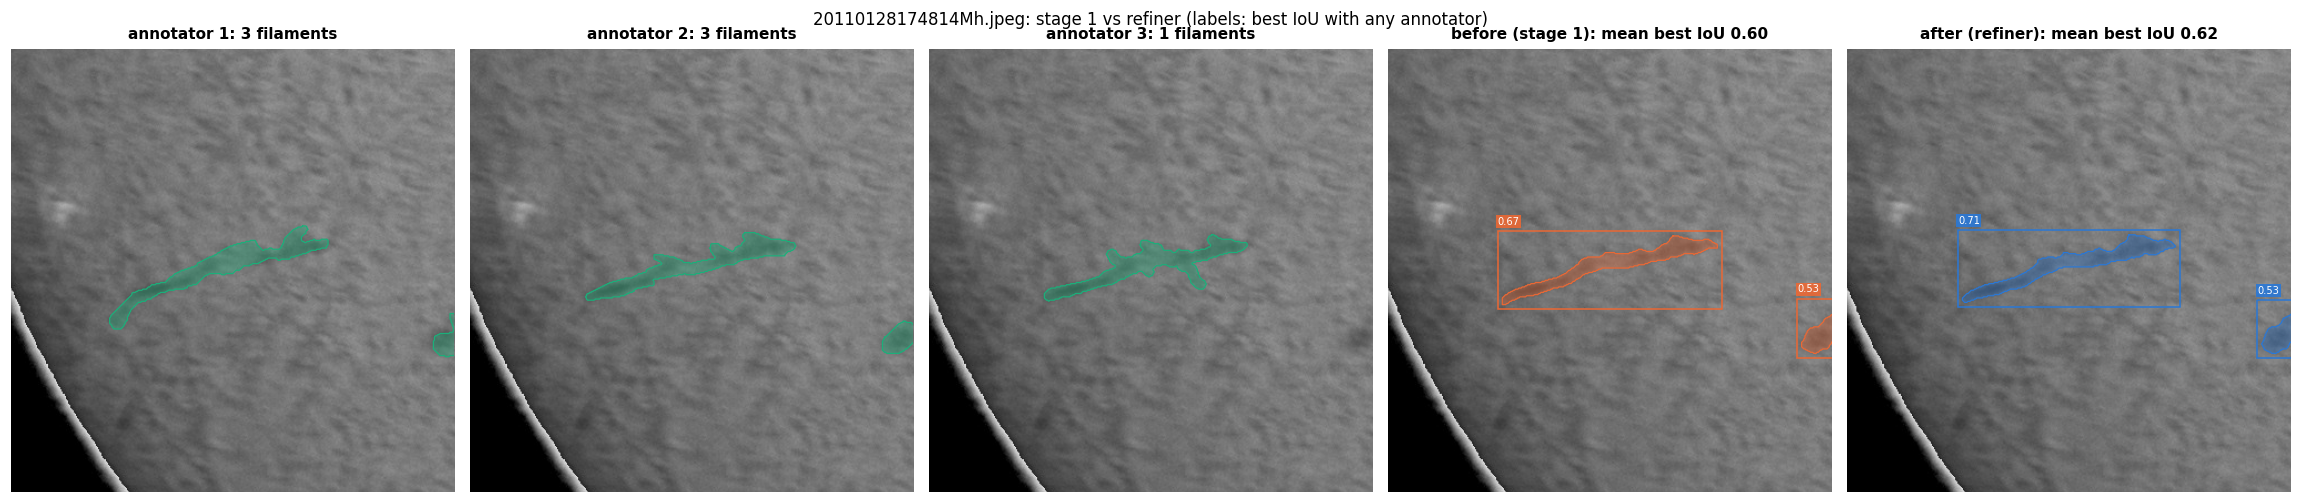

In [13]:
REFINED, SEED_PQ = None, {}

def pooled_pq(rles_by_file):
    rows = [r for f in VAL_MAPS for r in metrics.score_image(
        f, [mask_utils.decode(x).astype(bool) for x in rles_by_file.get(f, [])], INDEX)]
    return metrics.aggregate_pq(rows)['pq']

if REFINERS:
    t0 = time.time()
    REFINED = pipeline.refine_validation(VAL_MAPS, PATHS.train_images, FILTER, REFINERS, DEVICE, CFG, progress=tqdm)
    RESULTS['refiner'] = {'source': REFINER_SOURCE, 'validation_instances': sum(len(v) for v in REFINED.values()),
                          'minutes': round((time.time() - t0) / 60, 1)}
    if REFINER_SOURCE.startswith('trained'):
        # Refiners trained in this run: each one alone on fold 0, for the model cards.
        for name, net in zip(CFG.refiners, REFINERS):
            SEED_PQ[name] = pooled_pq(pipeline.refine_validation(VAL_MAPS, PATHS.train_images, FILTER, [net], DEVICE, CFG))
        RESULTS['refiner']['fold0_pq_alone'] = SEED_PQ
        RESULTS['refiner']['fold0_pq_ensemble'] = pooled_pq(REFINED)
        print('fold-0 PQ, each refiner alone:', {k: round(v, 4) for k, v in SEED_PQ.items()},
              '| both:', round(RESULTS['refiner']['fold0_pq_ensemble'], 4))
    if SAVE_RELEASE_ARTIFACTS:
        import pickle, shutil
        pickle.dump(REFINED, open(REPO / 'artifacts' / 'fold0_refined.pkl', 'wb'))
        if REFINER_SOURCE.startswith('trained') and REFINER_TRAINING == 'full':
            # The refiners trained by THIS notebook become the shipped ones.
            for name in CFG.refiners:
                info = TRAINED[name]
                shutil.copy2(info['path'], REPO / 'weights' / f'{name}.fp16.pt')
                pd.DataFrame(info['history']).rename(columns={'loss': 'train_loss'}).to_csv(
                    REPO / 'artifacts' / 'histories' / f'{name}.csv', index=False)
                CARDS['refiners'][name].update(
                    fingerprint=info['fingerprint'], fold0_pq_alone=round(SEED_PQ[name], 4),
                    megabytes=round(Path(info['path']).stat().st_size / 1e6, 1), training_minutes=round(info['minutes'], 1),
                    trained_by='solar_filament_pipeline.ipynb, Section 7, REFINER_TRAINING = full',
                    trained_on=time.strftime('%Y-%m-%d'))
            CARDS['refiners']['common'].update(
                trained_by='this notebook, Section 7 (REFINER_TRAINING = full)',
                training_crops=RESULTS['refiner_training']['crops'],
                fold0_pq={'before': round(FILTER.report['filtered_pq'], 4),
                          'after': round(RESULTS['refiner']['fold0_pq_ensemble'], 4)})
            (REPO / 'weights' / 'MODELS.json').write_text(json.dumps(CARDS, indent=1))
            print('the refiners trained in this run are now the shipped ones (weights/, histories, MODELS.json)')
    # Before and after on the three-annotator image of Section 3, zoomed on its largest kept filament.
    seeds, _ = pipeline.kept_validation_instances(VAL_MAPS, example, FILTER, CFG)
    refined = [mask_utils.decode(r).astype(bool) for r in REFINED[example]]
    if seeds:
        x0, y0, x1, y1 = decode.bounding_box(max(seeds, key=lambda m: m.sum()))
        cx, cy, half = (x0 + x1) // 2, (y0 + y1) // 2, max(x1 - x0, y1 - y0, 240) // 2 + 80
        window = (max(cx - half, 0), max(cy - half, 0), min(cx + half, 2047), min(cy + half, 2047))
        save(viz.refinement_panel(data.read_gray(PATHS.train_images / example), data.ground_truth_sets(INDEX, example),
                                  seeds, refined, f'{example}: stage 1 vs refiner (labels: best IoU with any annotator)',
                                  window), 'refiner_example')

## 8. Validation report against human agreement
These are the rubric's quantitative items on the 141 fold-0 images. Our predictions are scored against every annotator. The human reference scores each annotator's drawing against every *other* annotator of the same image.

| Item | What it measures |
|---|---|
| Pooled PQ / SQ / RQ | The competition metric, and its quality and recognition factors. |
| IoU and Dice | Means over **all overlapping** (ground truth, prediction) pairs, as in the organisers' self-evaluation notebook. |
| Missed 1:0 | Ground-truth filaments that no prediction touches. |
| Fragmented 1:n | Ground-truth filaments split across several predictions. |
| False alarm 0:1 | Predictions that touch no ground truth. |
| Merged n:1 | Predictions that join several ground-truth filaments. |

validation:   0%|          | 0/141 [00:00<?, ?it/s]

,pq,sq,rq,tp,fp,fn
unfiltered candidates,0.4222,0.6697,0.6305,1289.0,1037.0,474.0
stage 1 (filtered),0.4573,0.6728,0.6797,1162.0,494.0,601.0
deployed (filter + refiner),0.4679,0.6811,0.6870,1174.0,481.0,589.0
human vs human,0.3502,0.6342,0.5522,1090.0,884.0,884.0


deployed PQ 0.4679, 95% bootstrap interval over images [0.4494, 0.4851]


,ours,"ours, stage 1",human vs human
PQ,0.4679,0.4573,0.3502
SQ,0.6811,0.6728,0.6342
RQ,0.6870,0.6797,0.5522
IoU (pair mean),0.6028,0.5950,0.5197
Dice (pair mean),0.7339,0.7285,0.6620
missed 1:0,0.1798,0.1804,0.1687
1:1 (GT side),0.7952,0.7947,0.8034
fragmented 1:n,0.0250,0.0250,0.0279
false alarm 0:1,0.1269,0.1268,0.1687
1:1 (prediction side),0.8459,0.8472,0.8034


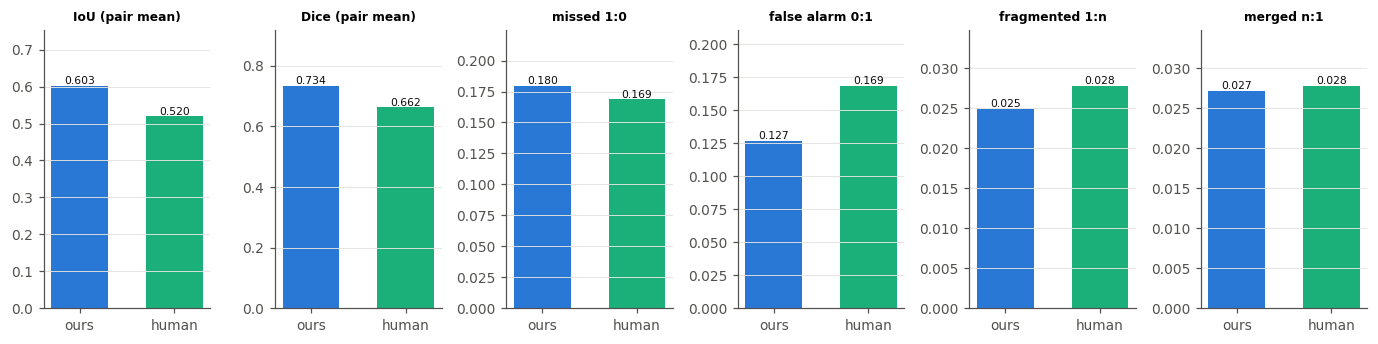

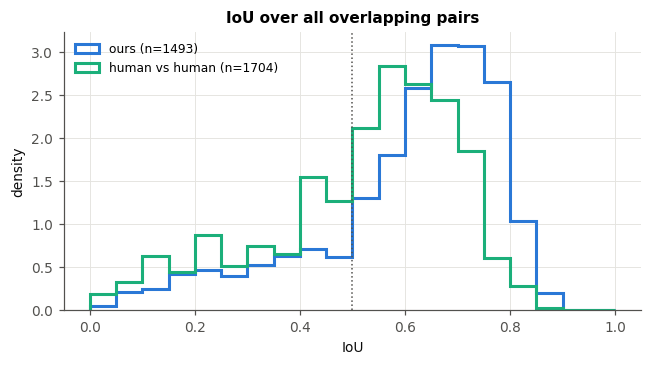

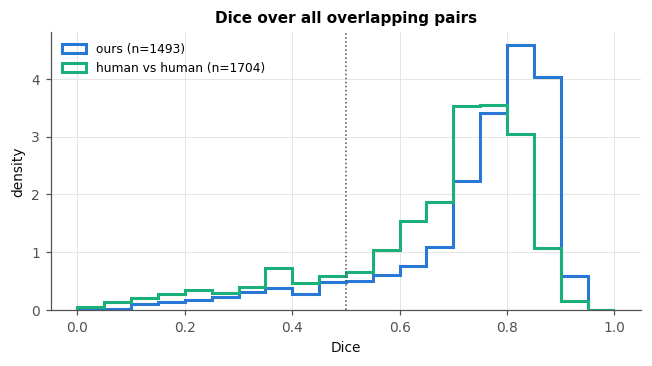

,tp,fp,fn,images
site,,,,
B,245,106,123,25
C,200,84,120,23
L,177,81,68,24
M,172,67,98,26
T,215,77,101,22
U,165,66,79,21


In [14]:
t0 = time.time()
VAL = pipeline.validate_system(VAL_MAPS, INDEX, FILTER, CFG, progress=tqdm, refined=REFINED)
STAGE1 = pipeline.validate_system(VAL_MAPS, INDEX, FILTER, CFG) if REFINED is not None else VAL
columns = {'unfiltered candidates': VAL.unfiltered, 'stage 1 (filtered)': STAGE1.filtered}
if REFINED is not None:
    columns['deployed (filter + refiner)'] = VAL.filtered
columns['human vs human'] = VAL.human
summary = pd.DataFrame(columns).T[['pq', 'sq', 'rq', 'tp', 'fp', 'fn']]
display(summary.round(4))
low, high = metrics.bootstrap_pq(VAL.per_image)
print(f'deployed PQ {VAL.filtered["pq"]:.4f}, 95% bootstrap interval over images [{low:.4f}, {high:.4f}]')
rubric = pd.DataFrame({'ours': VAL.ours_stats, 'ours, stage 1': STAGE1.ours_stats, 'human vs human': VAL.human_stats})
display(rubric.round(4))
RESULTS['validation'] = {'unfiltered_pq': VAL.unfiltered['pq'], 'stage1_pq': STAGE1.filtered['pq'],
                         'filtered_pq': VAL.filtered['pq'], 'human_pq': VAL.human['pq'], 'refined': REFINED is not None,
                         'filtered_pq_95ci': [low, high], 'rubric_ours': VAL.ours_stats, 'rubric_human': VAL.human_stats,
                         'minutes': round((time.time() - t0) / 60, 1)}
keys = ['IoU (pair mean)', 'Dice (pair mean)', 'missed 1:0', 'false alarm 0:1', 'fragmented 1:n', 'merged n:1']
save(viz.agreement_bars(VAL.ours_stats, VAL.human_stats, keys), 'rubric_bars')
save(viz.pair_histograms(VAL.pairs['ours_iou'], VAL.pairs['human_iou'], 'IoU'), 'iou_pairs')
save(viz.pair_histograms(VAL.pairs['ours_dice'], VAL.pairs['human_dice'], 'Dice'), 'dice_pairs')
per_site = VAL.per_image.assign(site=VAL.per_image['filename'].map(data.site_code)).groupby('site')[['tp', 'fp', 'fn']].sum()
per_site['images'] = VAL.per_image.assign(site=VAL.per_image['filename'].map(data.site_code)).groupby('site').size()
display(per_site)

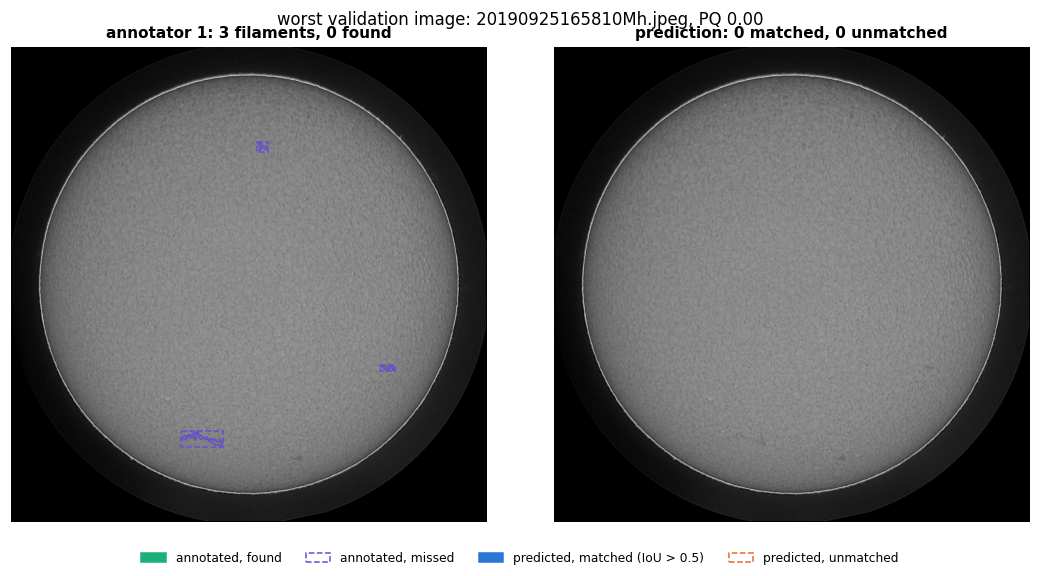

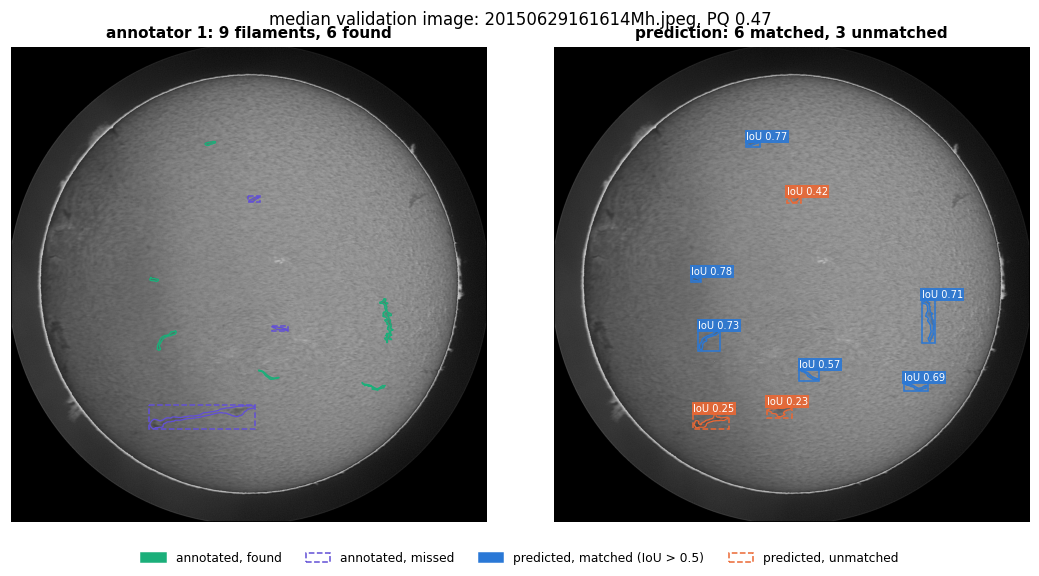

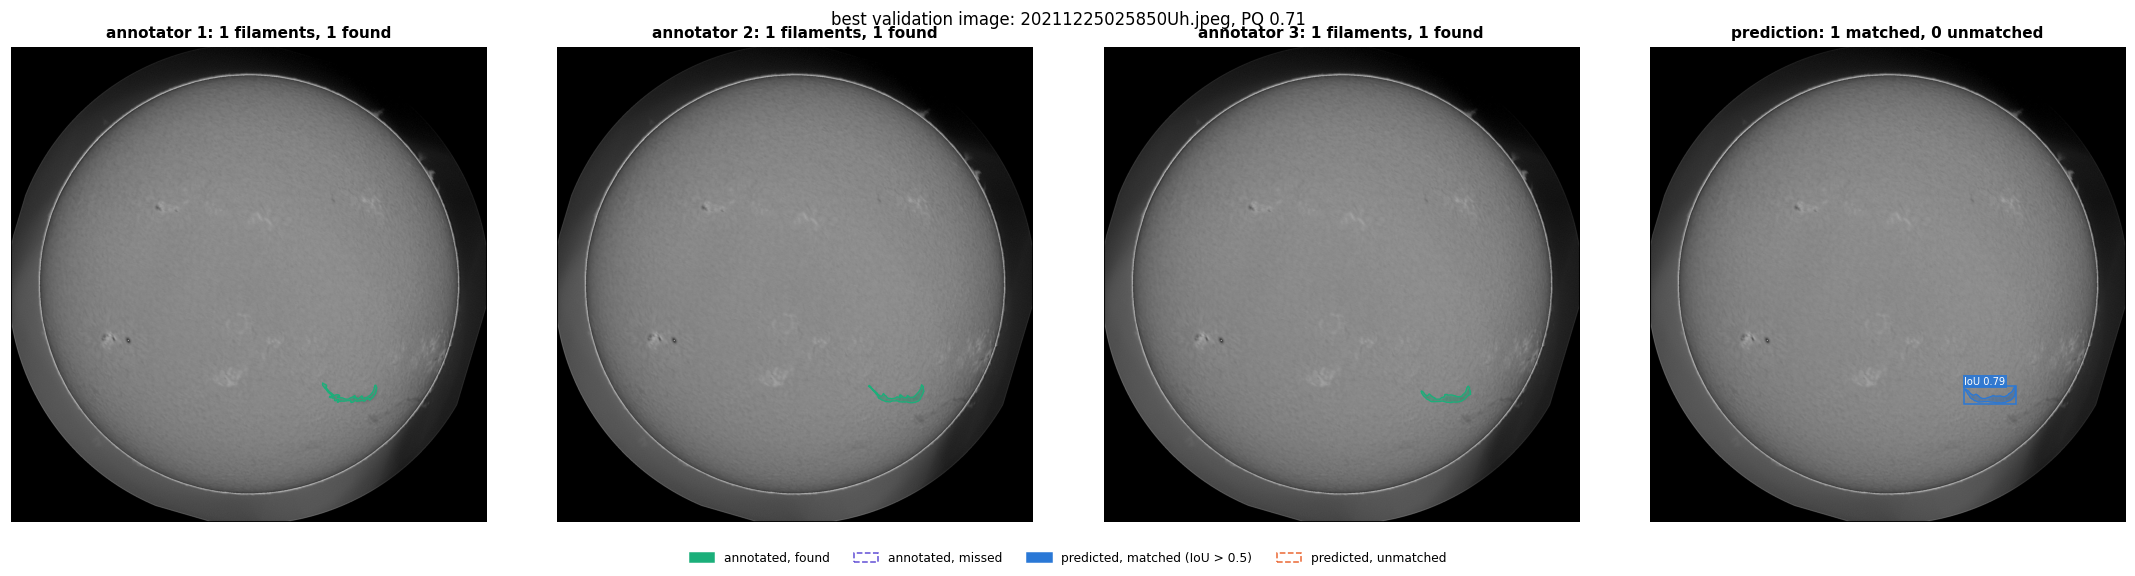

In [15]:
# Best, median and worst validation images by per-image PQ (images with at least 3 annotated filaments).
ranked = VAL.per_image[VAL.per_image['tp'] + VAL.per_image['fn'] >= 3].sort_values('pq')
picks = {'worst': ranked.iloc[0], 'median': ranked.iloc[len(ranked) // 2], 'best': ranked.iloc[-1]}
for label, row in picks.items():
    f = row['filename']
    kept, dropped = pipeline.kept_validation_instances(VAL_MAPS, f, FILTER, CFG)
    if REFINED is not None:
        kept = [mask_utils.decode(r).astype(bool) for r in REFINED[f]]
    gts = data.ground_truth_sets(INDEX, f)
    save(viz.validation_panel(data.read_gray(PATHS.train_images / f), gts, kept, pipeline.match_matrices(gts, kept),
                              f'{label} validation image: {f}, PQ {row["pq"]:.2f}'), f'validation_{label}')

## 9. Test inference and submission
Each test image goes through the same stages: read, preprocess (3 channels at 1536 px), network (3 members × 4 flips), upsample to 2048 px, decode, filter, refine (2 refiners × 4 flips on one crop per kept filament), RLE encode. The timer below charges each stage separately. Then every check the host applies is asserted: unique ids, ids that map to test images, and no overlapping pixels.

test images:   0%|          | 0/180 [00:00<?, ?it/s]

,submission
rows,1266.00
test_images,180.00
images_with_filaments,176.00
images_without,4.00
max_pixel_multiplicity,1.00
images_processed,180.00
candidates,1678.00
kept,1266.00
minutes,30.10
s_per_image,10.04


,filament_id,segmentation_rle
0,20110120105534Ch_1,b_bh25jo12O10O1N3N1O1O0000SPN2ko12N101O001O1O0...
1,20110120105534Ch_2,PkTo14ko1001N101O00000O1O0100N2O2O000100000000...
2,20110130110334Ch_1,c_Pe29eo14N2N4L20O0OlPNBgn1?UQNDkn1h01O1O1O4L1...
3,20110214175414Mh_1,[]d[23go18M2M3I7M201N101oNWOhRNk0Vm1WOiRNi0Vm1...
4,20110214175414Mh_2,^^`d24lo11N2O001O00001O001O1O0000000000O010000...


,seconds,calls,share,s_per_image
network,1237.789,180,0.696,6.877
refine,347.691,176,0.196,1.932
preprocess,122.924,180,0.069,0.683
filter,27.749,180,0.016,0.154
encode,25.783,180,0.014,0.143
decode,7.378,180,0.004,0.041
read,6.022,180,0.003,0.033
upsample,3.120,180,0.002,0.017


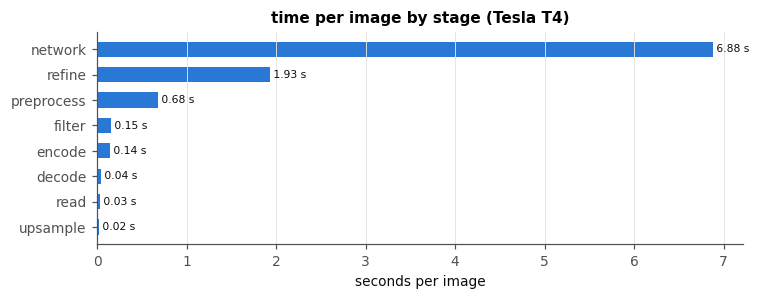

wrote /kaggle/working/repo/outputs/submission.csv


In [16]:
TIMER = timing.StageTimer(DEVICE)
SEGMENTER = pipeline.Segmenter(MEMBERS, FILTER, DEVICE, CFG, TIMER, refiners=REFINERS)
show = [p.name for p in TEST_FILES[:: max(len(TEST_FILES) // 6, 1)][:6]]
if RUN_TEST:
    t0 = time.time()
    SUBMISSION, PER_IMAGE, EXAMPLES = SEGMENTER.segment_folder(PATHS.test_images, WORK / 'submission.csv', keep=show,
                                                               progress=tqdm, limit=MAX_TEST_IMAGES)
    n_images = len(PER_IMAGE)
    check = submission.check_submission(SUBMISSION, PATHS.test_images) if MAX_TEST_IMAGES is None else {'rows': len(SUBMISSION)}
    RESULTS['test'] = {**check, 'images_processed': n_images, 'candidates': int(PER_IMAGE['candidates'].sum()),
                       'kept': int(PER_IMAGE['kept'].sum()), 'minutes': round((time.time() - t0) / 60, 1),
                       's_per_image': round((time.time() - t0) / max(n_images, 1), 2)}
    display(pd.Series(RESULTS['test'], name='submission').to_frame())
    display(SUBMISSION.head())
    STAGES = TIMER.table(images=n_images)
    display(STAGES)
    save(viz.timing_bars(STAGES, f'time per image by stage ({ENV["gpu"] or "CPU"})'), 'timing')
    print('wrote', WORK / 'submission.csv')
else:
    EXAMPLES = {}
    print('test inference skipped (RUN_TEST = False)')

## 10. Segmentations with bounding boxes
These are test images: there are no labels, so this section shows the segmentation only.
- **Solid boxes:** filaments kept, with their refined outlines. The label is the instance id and the filter score, the predicted share of annotators who would draw the filament.
- **Dashed boxes:** candidates the filter dropped.

The second figure zooms into the densest region of the first image.

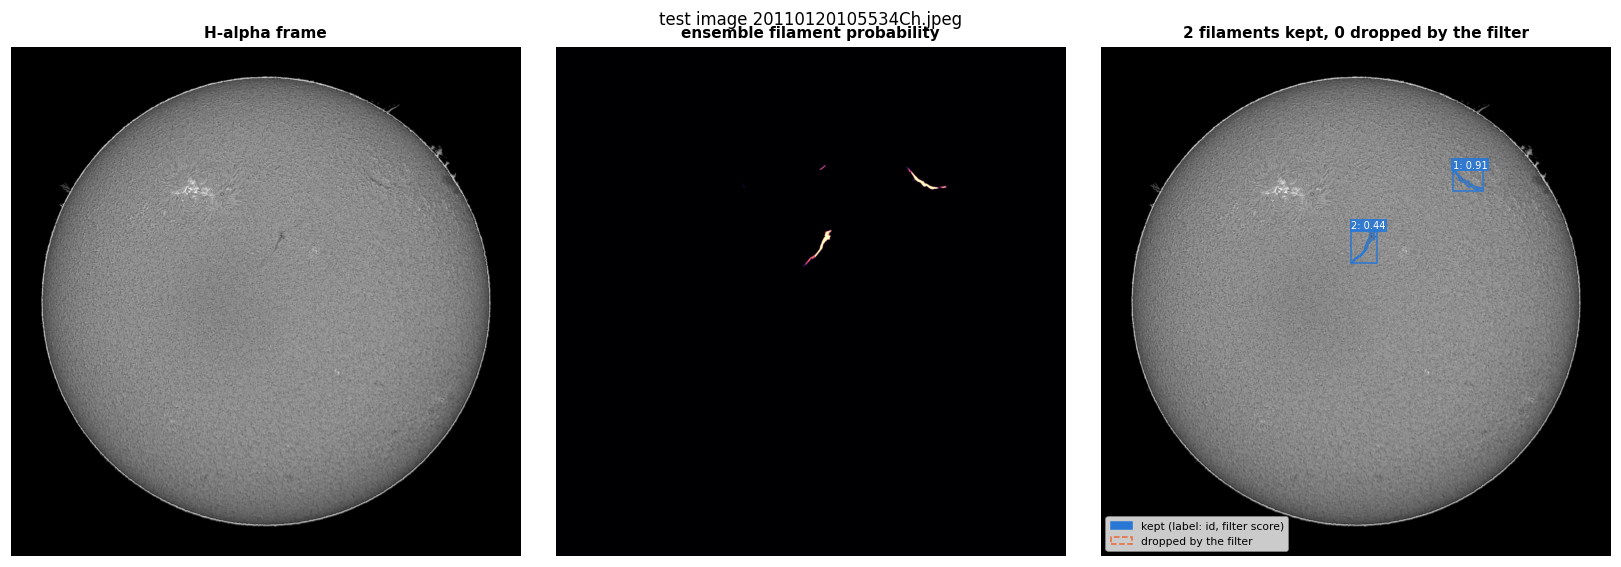

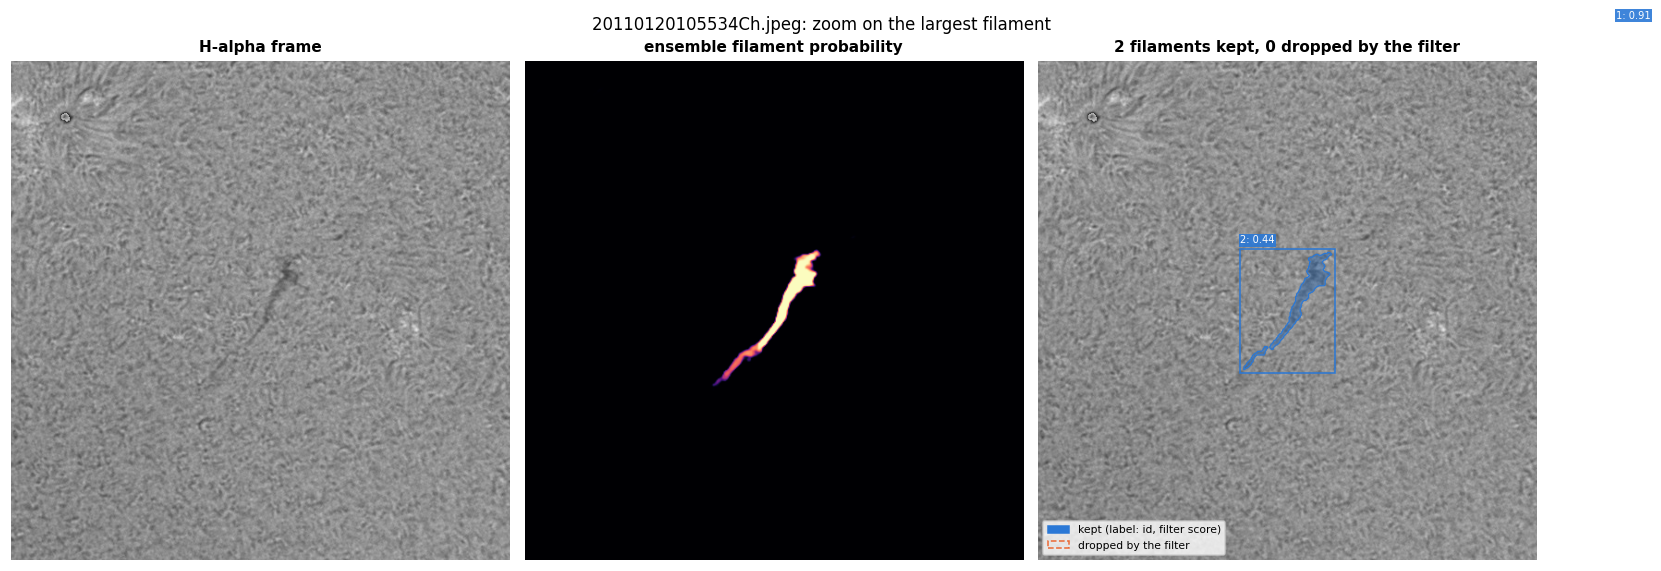

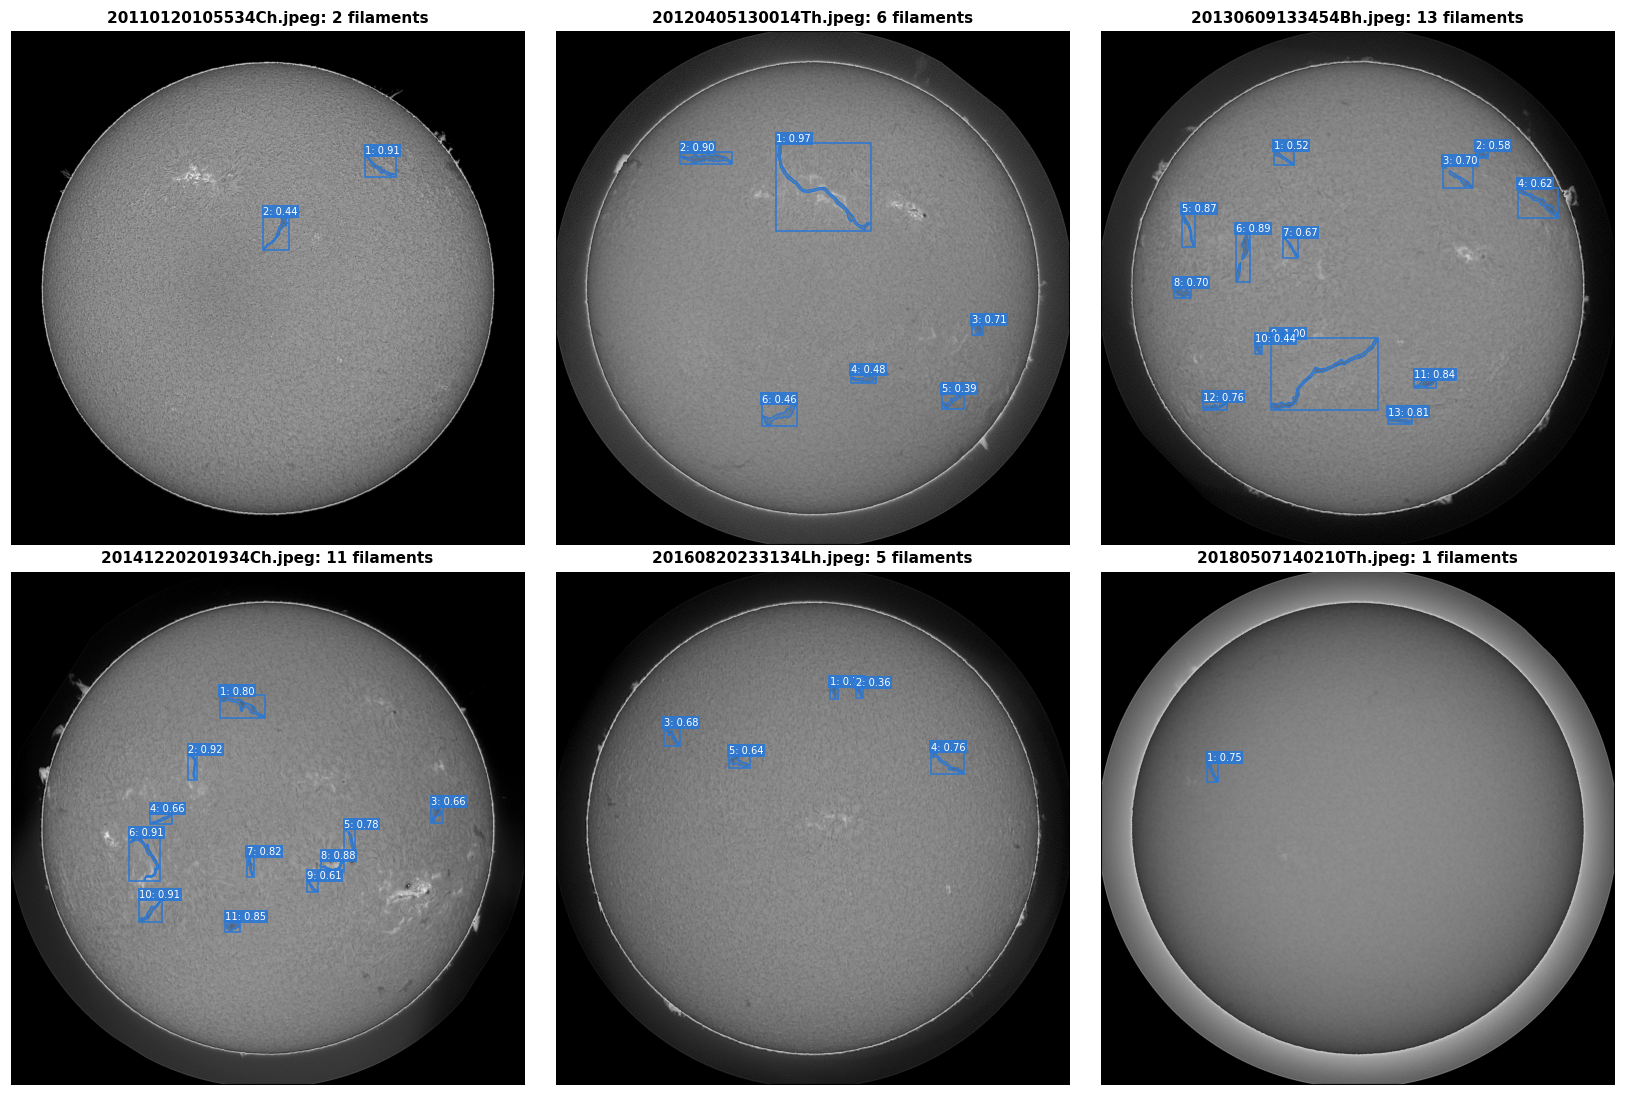

In [17]:
if EXAMPLES:
    names = list(EXAMPLES)
    first = EXAMPLES[names[0]]
    probability = inference.dequantise(first.maps[0])
    image = data.read_gray(PATHS.test_images / names[0])
    dropped = [m for m, s in zip(first.candidates, first.candidate_scores) if s < FILTER.threshold]
    dropped_scores = [s for s in first.candidate_scores if s < FILTER.threshold]
    save(viz.segmentation_panel(image, probability, first.instances, first.scores, dropped, dropped_scores,
                                f'test image {names[0]}'), 'test_panel')
    if first.instances:
        biggest = max(first.instances, key=lambda m: m.sum())
        x0, y0, x1, y1 = decode.bounding_box(biggest)
        cx, cy, half = (x0 + x1) // 2, (y0 + y1) // 2, max(x1 - x0, y1 - y0, 300) // 2 + 120
        window = (max(cx - half, 0), max(cy - half, 0), min(cx + half, 2047), min(cy + half, 2047))
        save(viz.segmentation_panel(image, probability, first.instances, first.scores, dropped, dropped_scores,
                                    f'{names[0]}: zoom on the largest filament', window=window), 'test_panel_zoom')
    items = [{'image': data.read_gray(PATHS.test_images / n), 'instances': r.instances, 'scores': r.scores,
              'title': f'{n}: {len(r.instances)} filaments'} for n, r in EXAMPLES.items()]
    save(viz.instance_gallery(items, columns=3), 'test_gallery')

## 11. Learning curves
These are the training histories of v27, v31, a rerun of the v24 recipe (the original v24 log is in `training_notebooks/v24.ipynb`), the teacher–student experiment and the two refiners, read from `artifacts/histories/`. During training, validation PQ was measured on one view without the filter, so it sits below the deployed numbers. A smoke or full run from Section 5 is drawn as well.

**What the curves show:**
- Every member plateaus at in-training PQ ≈ 0.40 by epoch 18–24, so longer training is not the lever.
- The student, with pseudo-labelled frames, ends above the identical schedule trained on labelled images only.
- The two refiners converge to nearly the same loss (0.310 and 0.305) after 16 epochs.

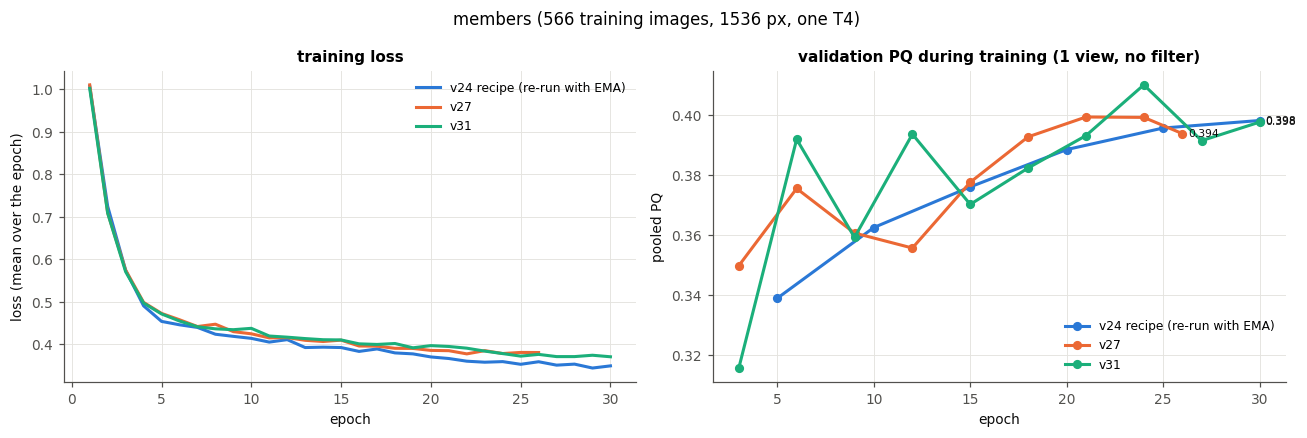

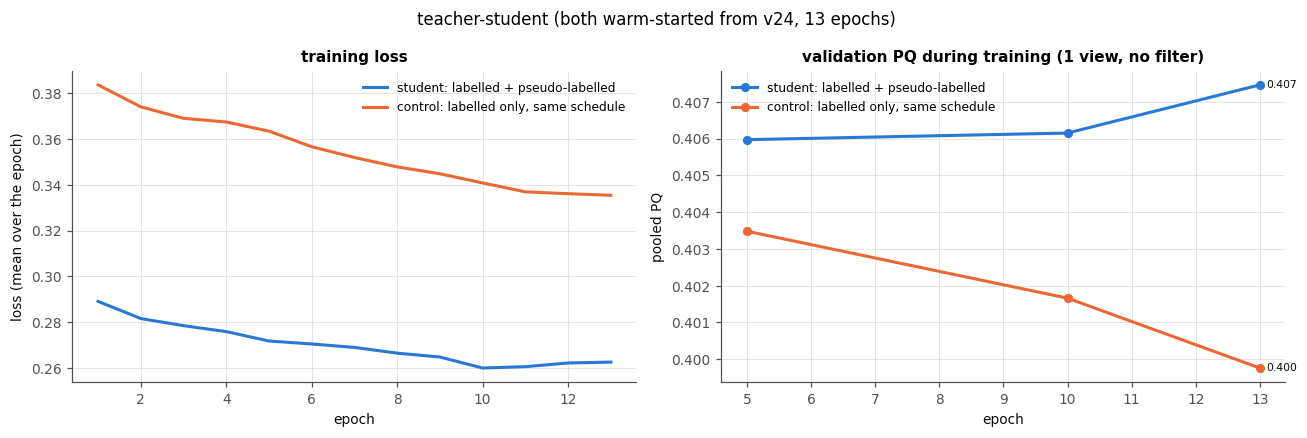

/kaggle/working/repo/filament/viz.py:186: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend(fontsize=8)


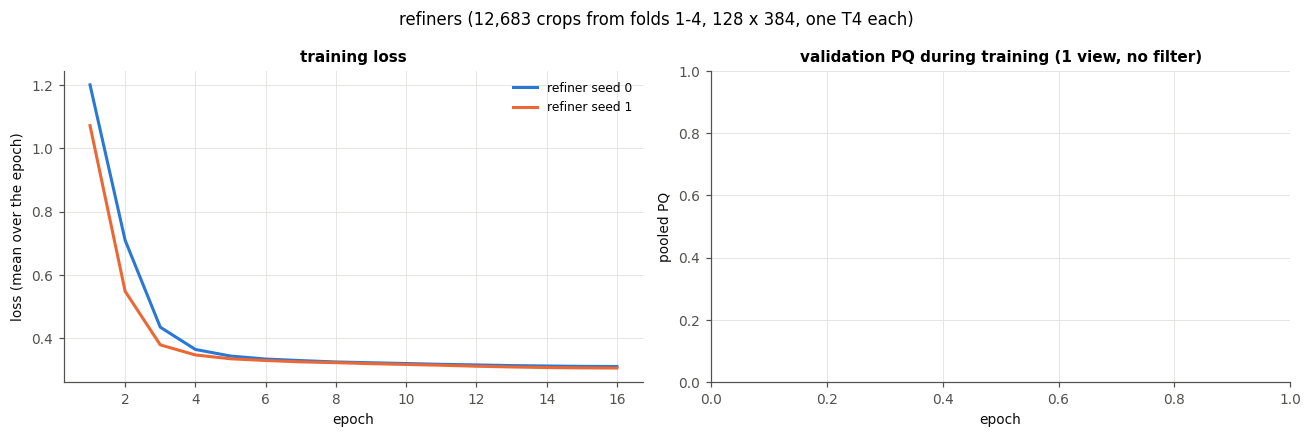

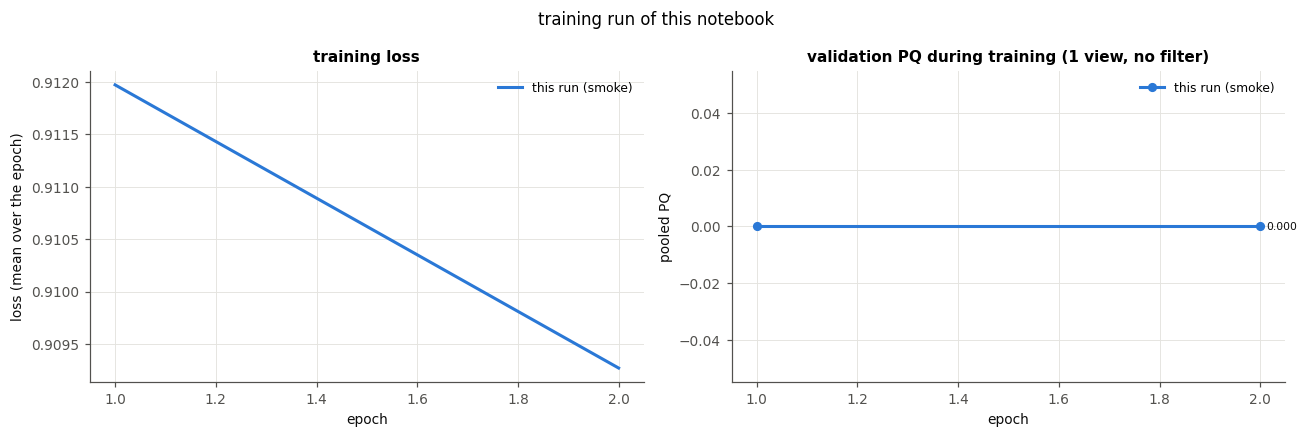

/kaggle/working/repo/filament/viz.py:186: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend(fontsize=8)


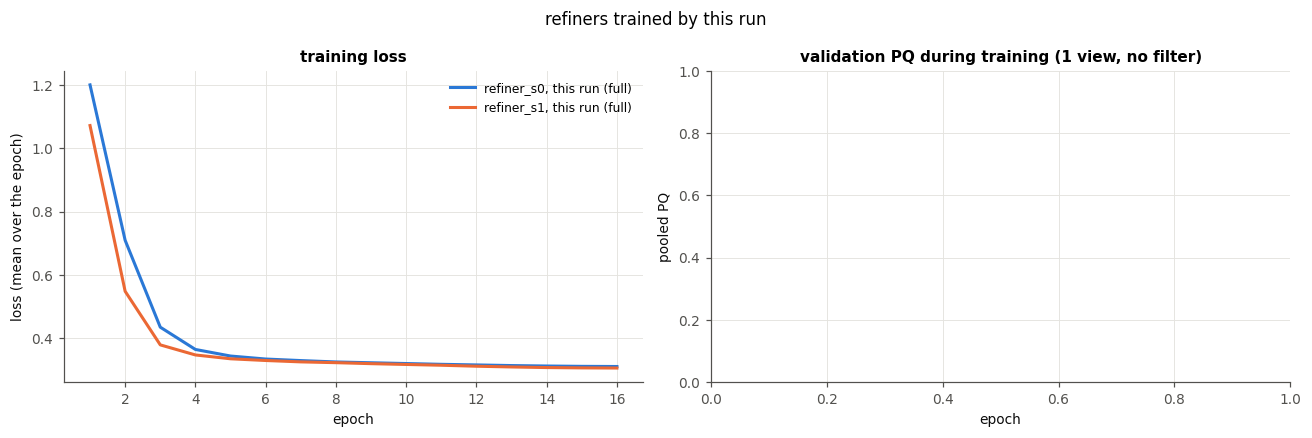

In [18]:
H = REPO / 'artifacts' / 'histories'
members_h = {'v24 recipe (re-run with EMA)': pd.read_csv(H / 'v24_recipe_rerun.csv'),
             'v27': pd.read_csv(H / 'v27.csv'), 'v31': pd.read_csv(H / 'v31.csv')}
save(viz.learning_curves(members_h, 'members (566 training images, 1536 px, one T4)'), 'curves_members')
ts_h = {'student: labelled + pseudo-labelled': pd.read_csv(H / 'student.csv'),
        'control: labelled only, same schedule': pd.read_csv(H / 'labelled_only_control.csv')}
save(viz.learning_curves(ts_h, 'teacher-student (both warm-started from v24, 13 epochs)'), 'curves_teacher_student')
save(viz.learning_curves({'refiner seed 0': pd.read_csv(H / 'refiner_s0.csv'), 'refiner seed 1': pd.read_csv(H / 'refiner_s1.csv')},
                         'refiners (12,683 crops from folds 1-4, 128 x 384, one T4 each)'), 'curves_refiners')
if TRAIN_HISTORY is not None:
    save(viz.learning_curves({f'this run ({TRAINING})': TRAIN_HISTORY}, 'training run of this notebook'), 'curves_this_run')
if TRAINED:
    save(viz.learning_curves({f'{name}, this run ({REFINER_TRAINING})': pd.DataFrame(info['history']).rename(columns={'loss': 'train_loss'})
                              for name, info in TRAINED.items()}, 'refiners trained by this run'), 'curves_this_run_refiner')

## 12. ONNX
The cell below exports one member to ONNX, checks the graph, runs it with ONNX Runtime, and compares it with PyTorch on a few test images. In the committed run ONNX Runtime fell back to the CPU (its CUDA 12 build does not load beside PyTorch's CUDA 13); that is the red provider message in the output, and the comparison is unaffected. Only the network forward is swapped; preprocessing, TTA, decoding and the filter are shared.

**The full benchmark on a Kaggle T4** (180 test images, 3 members × 4 views, stage 1 only, measured before the refiner was added) is in `artifacts/onnx_benchmark.json`:
- ONNX Runtime fp32 runs at 0.94× the speed of PyTorch, with 100% identical submission rows.
- Mixed fp16 in PyTorch runs at 1.04×.
- The network is 79% of the time, so a backend change cannot buy much. PyTorch fp32 therefore ships, and the ONNX export is provided for portability.

In [19]:
if RUN_ONNX:
    from filament import onnx_backend
    onnx_dir = WORK / 'onnx'; onnx_dir.mkdir(exist_ok=True)
    t0 = time.time()
    path = onnx_backend.export_onnx(MEMBERS[0], onnx_dir / f'{CFG.members[0]}.onnx', CFG.input.input_size)
    graph = onnx_backend.check_onnx(path)
    ort_model = onnx_backend.OrtSegmenter(path, DEVICE)
    rows = []
    for p in TEST_FILES[:ONNX_IMAGES]:
        image = data.read_gray(p)
        timer_t, timer_o = timing.StageTimer(DEVICE), timing.StageTimer(DEVICE)
        with timer_t('network', sync=True):
            a = inference.predict_maps([MEMBERS[0]], image, DEVICE, CFG.input, CFG.inference)
        with timer_o('network', sync=True):
            b = inference.predict_maps([ort_model], image, DEVICE, CFG.input, CFG.inference)
        ia, ib = decode.decode_instances(a[0], CFG.decode), decode.decode_instances(b[0], CFG.decode)
        rows.append({'image': p.name, 'max_abs_prob_diff': float(np.abs(a - b).max()),
                     'same_instances': len(ia) == len(ib) and all(np.array_equal(u, v) for u, v in zip(ia, ib)),
                     'torch_s': round(timer_t.seconds['network'], 2), 'onnxruntime_s': round(timer_o.seconds['network'], 2)})
    PARITY = pd.DataFrame(rows)
    RESULTS['onnx'] = {**graph, 'provider': ort_model.provider, 'export_and_parity_s': round(time.time() - t0, 1),
                       'max_abs_prob_diff': float(PARITY['max_abs_prob_diff'].max()),
                       'all_instances_identical': bool(PARITY['same_instances'].all())}
    display(pd.Series(RESULTS['onnx'], name='onnx').to_frame()); display(PARITY)
    bench = json.loads((REPO / 'artifacts' / 'onnx_benchmark.json').read_text())
    full = pd.DataFrame(bench['results']).T
    cols = [c for c in ['config', 'total_s', 's_per_image', 'rows', 'rows_identical_to_A'] if c in full.columns]
    print('full benchmark on', bench['env']['gpu'], '(180 test images, 3 members x 4 views):')
    display(full[cols] if cols else full)
else:
    print('ONNX section skipped (RUN_ONNX = False)')

2026-11-14 11:22:33.838903833 [E:onnxruntime:Default, provider_bridge_ort.cc:2195 TryGetProviderInfo_CUDA] /onnxruntime_src/onnxruntime/core/session/provider_bridge_ort.cc:1778 onnxruntime::Provider& onnxruntime::ProviderLibrary::Get() [ONNXRuntimeError] : 1 : FAIL : Failed to load library libonnxruntime_providers_cuda.so with error: libcublas.so.12: cannot open shared object file: No such file or directory

2026-11-14 11:22:33.838973153 [W:onnxruntime:Default, onnxruntime_pybind_state.cc:1055 CreateExecutionProviderInstance] Failed to create CUDAExecutionProvider. Require cuDNN 9.* and CUDA 12.*. Please install all dependencies as mentioned in the GPU requirements page (https://onnxruntime.ai/docs/execution-providers/CUDA-ExecutionProvider.html#requirements), make sure they're in the PATH, and that your GPU is supported.


,onnx
opset,17
nodes,526
inputs,"[(images, [1, 3, 1536, 1536])]"
megabytes,121.9
provider,CPUExecutionProvider
export_and_parity_s,94.9
max_abs_prob_diff,0.000951
all_instances_identical,True


,image,max_abs_prob_diff,same_instances,torch_s,onnxruntime_s
0,20110120105534Ch.jpeg,0.000951,True,3.05,29.97
1,20110130110334Ch.jpeg,0.000743,True,3.01,27.13
2,20110214175414Mh.jpeg,0.000469,True,3.02,25.93


full benchmark on Tesla T4 (180 test images, 3 members x 4 views):


,config,total_s,s_per_image,rows,rows_identical_to_A
A_torch_fp32,A. PyTorch fp32 (shipped),883.8,4.91,1279,1.0
B_torch_fp32_bench,B. PyTorch fp32 + cudnn.benchmark,886.4,4.925,1279,1.0
C_onnx_fp32,C. ONNX Runtime fp32,935.5,5.197,1279,1.0
E_onnx_mixed_fp16,E. ONNX Runtime mixed fp16,898.8,4.993,1280,0.929633
D_torch_mixed_fp16,D. PyTorch mixed fp16,847.7,4.71,1280,0.928851


## 13. Summary
Every number above is also saved to `outputs/run_summary.json`, and every figure to `outputs/figures/`.

In [20]:
RESULTS['total_minutes'] = round((time.time() - T_START) / 60, 1)
RESULTS['models'] = MODEL_TABLE.reset_index().to_dict('records')
(WORK / 'run_summary.json').write_text(json.dumps(RESULTS, indent=1, default=str))
headline = {'validation PQ, deployed (fold 0)': round(VAL.filtered['pq'], 4),
            'validation PQ, stage 1 (no refiner)': round(STAGE1.filtered['pq'], 4),
            'validation PQ, human vs human': round(VAL.human['pq'], 4),
            'IoU pair mean, ours / human': f"{VAL.ours_stats['IoU (pair mean)']:.3f} / {VAL.human_stats['IoU (pair mean)']:.3f}",
            'merged n:1, ours / human': f"{VAL.ours_stats['merged n:1']:.3f} / {VAL.human_stats['merged n:1']:.3f}",
            'test rows': RESULTS.get('test', {}).get('rows'), 'seconds per test image': RESULTS.get('test', {}).get('s_per_image'),
            'total minutes': RESULTS['total_minutes']}
display(pd.Series(headline, name='summary').to_frame())
provenance = {**{f'{n} (member)': f"{c['trained_by']['kaggle_notebook']} v{c['trained_by']['version']} -> weights/{n}.fp16.pt"
                 for n, c in CARDS['members'].items() if 'trained_by' in c},
              **{f'{n} (refiner)': f"{RESULTS.get('refiner', {}).get('source', 'off')} -> weights/{n}.fp16.pt" for n in CFG.refiners},
              'instance filter': 'refit in this run (Section 6)' if REFIT_FILTER else 'shipped weights/instance_filter.pkl (Section 6)'}
display(pd.Series(provenance, name='where every weight file comes from').to_frame())
RESULTS['provenance'] = provenance
(WORK / 'run_summary.json').write_text(json.dumps(RESULTS, indent=1, default=str))
print('figures:', sorted(p.name for p in FIGURES.glob('*.png')))

,summary
"validation PQ, deployed (fold 0)",0.4679
"validation PQ, stage 1 (no refiner)",0.4573
"validation PQ, human vs human",0.3502
"IoU pair mean, ours / human",0.603 / 0.520
"merged n:1, ours / human",0.027 / 0.028
test rows,1266
seconds per test image,10.04
total minutes,279.2


,where every weight file comes from
v24 (member),alok158/solar-filament v24 -> weights/v24.fp16.pt
v27 (member),alok158/solar-filament v27 -> weights/v27.fp16.pt
v31 (member),alok158/solar-filament v31 -> weights/v31.fp16.pt
refiner_s0 (refiner),trained in this run (REFINER_TRAINING = full) ...
refiner_s1 (refiner),trained in this run (REFINER_TRAINING = full) ...
instance filter,refit in this run (Section 6)


figures: ['annotators.png', 'curves_members.png', 'curves_refiners.png', 'curves_teacher_student.png', 'curves_this_run.png', 'curves_this_run_refiner.png', 'data_overview.png', 'dice_pairs.png', 'filter.png', 'input_channels.png', 'iou_pairs.png', 'refiner_example.png', 'rubric_bars.png', 'test_gallery.png', 'test_panel.png', 'test_panel_zoom.png', 'timing.png', 'validation_best.png', 'validation_median.png', 'validation_worst.png']
